# MVP Geração Z e Álcool | Notebook 01 v3: análise exploratória e decisões de tratamento

**Disciplina:** PSP8 (Prof. André Luiz Marques Serrano, EPR/FT/UnB)
**Autor:** Guilherme Augusto Fontes Cunha
**Versão:** v3 (16 out. 2026). Substitui `MVP_GenZ_Alcool_01_AED_v2.ipynb`. As seções 1 a 13 repetem a exploração da v2 (feita na formulação original, que comparava anos); a seção 14 registra as **decisões de tratamento D1 a D13, tomadas pelo autor**, e a seção 15 mostra uma prévia com as decisões aplicadas, na formulação nova (comparação entre gerações). O teste formal fica no pipeline do Databricks (`notebooks/05_analise_hipoteses.py`).
**Documento companheiro:** *Relatório de Análise Exploratória de Dados v3* (.md), com os motivos de cada decisão.

**Novidades da v3:**
1. Decisões D1 a D13 tomadas, com a decisão e o motivo de cada uma (seção 14; tabela completa em `DECISOES_TRATAMENTO.md`).
2. Objetivo reformulado (README, versão 2): comparar millennials, zillennials e geração Z na mesma idade (18 a 24 anos).
3. Prévia com as decisões aplicadas: camada tratada local (espelho da silver do pipeline), prevalência por geração, decomposição do consumo abusivo e sensibilidades (seção 15).

**Novidades da v2** (mantidas): vazios em três categorias (seção 4), notas de rodapé das variáveis, leitura didática dos pesos (seção 12), capitais com prevalência e intervalo (seção 13.4), efeito do modo de coleta (seção 8), mudança da pergunta de doses em 2010 (seção 11.3) e filtro novo de 2024 (seção 11.5).

**Pergunta do trabalho (versão 2 do objetivo):** a geração Z bebe menos, e isso vale para todas as classes sociais?

## Onde estamos no ciclo de projeto

Etapas 1 (busca) e 2 (coleta e análise exploratória) do ciclo do Módulo 1, com a mesma estrutura do AED v16 do MVP de terras raras: leitura fiel do bruto, conferência, dicionário, faltantes, coerência entre variáveis, pesos, tabela de frequência (Módulo 2) e registro de problemas antes do pré-processamento (Módulo 3).

## Hipótese e perguntas (README, versão 2 do objetivo)

> Na mesma idade (18 a 24 anos), a prevalência de consumo abusivo de álcool nas capitais brasileiras diminui de uma geração para a seguinte (millennials → zillennials → geração Z), nos dois sexos e em todas as faixas de escolaridade, e essa diferença não se explica por uma tendência geral da população no mesmo período.

| # | Pergunta | Variáveis da base |
|---|---|---|
| P1 | Na mesma idade (18 a 24), quanto cada geração difere da anterior? | `ano`, `q6`⁵, `fet`¹⁵, `alcabu`¹⁸, `pesorake2025`¹⁹ |
| P2 | A diferença ocorre em todas as faixas de escolaridade? | + `fesc`¹⁷ |
| P3 | É efeito de geração ou de época? (adultos de 35 a 44 anos no mesmo período; cada geração ao envelhecer) | `fet`¹⁵ = 3; idade |
| P4 | A diferença é igual entre homens e mulheres? | + `q7`⁶ |
| P5 | Quais capitais e regiões concentram as maiores e menores diferenças? | + `cidade` |

As seções 1 a 13 foram escritas para a formulação original (2010 contra o ano mais recente), guardada no Anexo A do README; os achados delas levaram às decisões da seção 14.

> ⁵ **q6**: pergunta, a todos: "Qual sua idade?" (só aceita 18 anos ou mais).

> ⁶ **q7**: registro do questionário, a todos: "Sexo: 1 = masculino, 2 = feminino".

> ¹⁵ **fet**: variável derivada: faixa etária calculada pelo Ministério a partir de q6. 1 = 18 a 24 (os "jovens"), 2 = 25 a 34, 3 = 35 a 44, 4 = 45 a 54, 5 = 55 a 64, 6 = 65 e mais.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

## Fonte escolhida

**Vigitel Brasil 2006-2024, base harmonizada** (Ministério da Saúde, SVSA/DAENT), publicada em 24/08/2026 em <https://svs.aids.gov.br/daent/cgdnt/vigitel/>. É a base ideal para o MVP porque: (1) é a fonte oficial do indicador de consumo abusivo citado no README; (2) junta todas as edições num único arquivo, com o mesmo dicionário; (3) traz o peso `pesorake2025`¹⁹, recalibrado pelo Censo 2022 para 2010 a 2024, que a orientação oficial manda usar em análises de série; (4) traz o indicador `alcabu`¹⁸ já calculado. Licença do portal: Creative Commons Atribuição-SemDerivações 3.0.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

## Como ler as notas

Toda variável citada no texto recebe um número sobrescrito fixo (por exemplo, q37 é sempre ¹ e q38 é sempre ²). A legenda aparece logo abaixo do bloco, com a redação oficial da pergunta ou a definição da variável derivada.

## Como executar

- **Colab:** *Ambiente de execução > Executar tudo*. O notebook baixa o ZIP (87 MB) do site do Ministério e confere o SHA-256.
- **Databricks:** importe o `.ipynb` e execute. O ZIP é gravado no volume `/Volumes/workspace/genz_alcool/raw/` (coleta persistida na nuvem). Se o cluster não tiver acesso à internet, envie o ZIP para esse volume pela interface (*Catalog > workspace > genz_alcool > raw > Upload*) e execute de novo.
- **Local:** coloque o ZIP em `dados/raw/` do repositório ou na pasta do notebook.

O notebook não importa módulos do repositório: tudo o que ele usa está nele.

## 1. Configuração e reprodutibilidade

In [1]:
import os
import shutil
import zipfile
import hashlib
import platform
import datetime
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import ListedColormap

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

EM_DATABRICKS = 'DATABRICKS_RUNTIME_VERSION' in os.environ
try:
    import google.colab  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False
AMBIENTE = 'Databricks' if EM_DATABRICKS else ('Colab' if EM_COLAB else 'local')

# Cores com função fixa em todos os gráficos (a identidade também vai no rótulo)
COR_JOVEM = '#2a78d6'     # 18 a 24 anos (azul)
COR_REF = '#eb6834'       # 35 a 44 anos, grupo de comparação de P3 (laranja)
COR_OUTROS = '#b8b6ad'    # contexto (cinza)
CORES_ESC = {'0 a 8 anos': '#9ecae1', '9 a 11 anos': '#4292c6', '12 anos e mais': '#08306b'}

print('Ambiente:', AMBIENTE, '| Python', platform.python_version(), '| pandas', pd.__version__,
      '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)
print('Execução:', datetime.datetime.now().strftime('%d/%m/%Y %H:%M'))

Ambiente: local | Python 3.12.10 | pandas 3.0.5 | numpy 2.4.6 | matplotlib 3.11.2
Execução: 16/10/2026 23:04


## 2. Coleta: obtenção do arquivo oficial e conferência de identidade

O arquivo é baixado da página oficial, nunca de espelhos. O SHA-256 abaixo é o do ZIP baixado em 16/10/2026. O Ministério já republicou a base harmonizada (a versão de agosto de 2026 removeu os rótulos das categorias), então **se o hash não bater, os números deste notebook podem não valer** para o arquivo novo.

In [2]:
URL_BASE = 'https://svs.aids.gov.br/daent/cgdnt/vigitel/'
ARQ_ZIP = 'vigitel-2006-2024-peso-rake-csv.zip'
ARQ_DICIONARIO = 'dicionario-vigitel-2006-2024.xlsx'
SHA256_ESPERADO = '40139996d11deb2f52730c90f14e2df4bf5e53aba3cf1848fce391c93ff77993'
EXIGIR_MESMO_ARQUIVO = True   # mude para False só se for analisar conscientemente outra versão

if EM_DATABRICKS:
    CATALOGO, ESQUEMA, VOLUME = 'workspace', 'genz_alcool', 'raw'
    spark.sql(f'CREATE SCHEMA IF NOT EXISTS {CATALOGO}.{ESQUEMA}')
    spark.sql(f'CREATE VOLUME IF NOT EXISTS {CATALOGO}.{ESQUEMA}.{VOLUME}')
    PASTA_DADOS = f'/Volumes/{CATALOGO}/{ESQUEMA}/{VOLUME}'
    PASTA_SAIDAS = f'{PASTA_DADOS}/saidas_aed_v3'
else:
    candidatas = ['.', os.path.join('..', '..', 'dados', 'raw'), os.path.join('dados', 'raw')]
    PASTA_DADOS = next((p for p in candidatas if os.path.exists(os.path.join(p, ARQ_ZIP))), '.')
    PASTA_SAIDAS = 'saidas_aed_v3'


def obter(nome):
    """Devolve o caminho do arquivo; baixa da página oficial se ainda não existir."""
    destino = os.path.join(PASTA_DADOS, nome)
    if os.path.exists(destino):
        return destino
    url = URL_BASE + nome
    print('Baixando', url)
    temporario = os.path.join('/tmp' if os.path.isdir('/tmp') else '.', nome + '.parcial')
    try:
        pedido = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (MVP PSP8 UnB)'})
        with urllib.request.urlopen(pedido, timeout=600) as r, open(temporario, 'wb') as f:
            shutil.copyfileobj(r, f, length=1 << 20)
    except Exception as erro:
        raise RuntimeError(f'Download falhou ({erro}). Baixe {url} manualmente e coloque em {PASTA_DADOS}.')
    shutil.copyfile(temporario, destino)   # cópia (e não move) porque /Volumes não aceita rename entre sistemas
    os.remove(temporario)
    return destino


CAMINHO_ZIP = obter(ARQ_ZIP)
DATA_COLETA = datetime.datetime.fromtimestamp(os.path.getmtime(CAMINHO_ZIP)).strftime('%d/%m/%Y')

h = hashlib.sha256()
with open(CAMINHO_ZIP, 'rb') as f:
    for bloco in iter(lambda: f.read(1 << 20), b''):
        h.update(bloco)
SHA = h.hexdigest()
TAMANHO = os.path.getsize(CAMINHO_ZIP)
print(f'Arquivo: {CAMINHO_ZIP} | {TAMANHO:,} bytes | gravado em {DATA_COLETA}')
print('SHA-256:', SHA)
if SHA != SHA256_ESPERADO:
    msg = 'ATENÇÃO: o ZIP não é a versão usada neste MVP (SHA-256 diferente).'
    if EXIGIR_MESMO_ARQUIVO:
        raise ValueError(msg + ' Confira a data de publicação no site ou mude EXIGIR_MESMO_ARQUIVO.')
    print(msg)
else:
    print('Identidade confirmada: mesma versão do arquivo usada no MVP.')

Arquivo: ..\..\dados\raw\vigitel-2006-2024-peso-rake-csv.zip | 87,121,523 bytes | gravado em 16/10/2026
SHA-256: 40139996d11deb2f52730c90f14e2df4bf5e53aba3cf1848fce391c93ff77993
Identidade confirmada: mesma versão do arquivo usada no MVP.


### 2.1 O que há dentro do ZIP e como o CSV está escrito

Antes de usar `pandas`, o arquivo é lido linha a linha como bytes, para medir três coisas que decidem os parâmetros de leitura: o número de linhas físicas, quantas linhas **não** são UTF-8 válido e quantas têm aspas (campo de texto com vírgula dentro).

In [3]:
with zipfile.ZipFile(CAMINHO_ZIP) as z:
    info = z.infolist()
    for i in info:
        print(f'{i.filename} | {i.file_size:,} bytes descompactado | {i.compress_size:,} compactado')
    NOME_CSV = info[0].filename
    linhas, nao_utf8, com_aspas, exemplos = 0, 0, 0, []
    with z.open(NOME_CSV) as f:
        for bruta in f:
            linhas += 1
            if b'"' in bruta:
                com_aspas += 1
            try:
                bruta.decode('utf-8')
            except UnicodeDecodeError as e:
                nao_utf8 += 1
                if len(exemplos) < 3:
                    exemplos.append(bruta[max(e.start - 40, 0):e.start + 15])

print(f'\nLinhas físicas: {linhas:,} (1 cabeçalho + {linhas - 1:,} registros)')
print(f'Linhas que não são UTF-8 válido: {nao_utf8:,}')
print(f'Linhas com aspas: {com_aspas:,}')
print('Exemplos de trechos não UTF-8:')
for e in exemplos:
    print('   ', e)

vigitel-2006-2024-peso-rake_slabel.csv | 577,433,824 bytes descompactado | 87,121,269 compactado



Linhas físicas: 833,218 (1 cabeçalho + 833,217 registros)
Linhas que não são UTF-8 válido: 1,555
Linhas com aspas: 408
Exemplos de trechos não UTF-8:
    b',,,2,1,1,2,,1,2,,10,1,900,PLANO DA AERON\xc1UTICA,1,0,1,,,'
    b'1,1,,4,4,1,0,1,1,2,1,1,,,,,1,900,ASSOCIA\xc7AO DOS FUNCION'
    b',,2,1,1,,,4,1,1,2,1,2,2,,,,,,1,900,FUNDA\xc7\xc3O COPEU,1,3,1'


**Leitura:** o CSV não tem uma codificação única. A maior parte é ASCII, algumas linhas trazem acentos em latin-1 (por exemplo `AERON\xc1UTICA`) e outras em UTF-8. Todos os casos estão em **campos de texto livre** (nome do plano de saúde, respostas "outros"), que não entram nas perguntas. Por isso a leitura usa `latin-1`, que aceita qualquer byte, e os campos de texto livre ficam fora do recorte. Os campos entre aspas têm vírgulas dentro: um leitor que ignore aspas acharia 487 colunas numa linha de 486.

## 3. Leitura fiel do bruto (recorte de colunas)

O CSV tem 486 colunas e 577 MB. Ler tudo como texto ocuparia vários GB de memória, mais do que o Databricks Free Edition oferece com folga. O recorte abaixo mantém **todas as linhas** e só as colunas ligadas às perguntas, mais as de controle.

| Parâmetro | Valor | Motivo |
|---|---|---|
| `compression` | `zip` | Lê direto do ZIP oficial, sem cópia descompactada |
| `encoding` | `latin-1` | Aceita qualquer byte (seção 2.1) |
| `dtype` | `category`, exceto o peso | Preserva os códigos exatamente como texto (`777`, `888`, vazio) e economiza memória |
| `keep_default_na=False` | vazio continua `''` | Vazio no Vigitel quase sempre é **pulo de questionário**, não perda de dado (seção 4) |

O dataframe `bruto` **nunca é alterado**. A impressão digital calculada abaixo é conferida no fim.

In [4]:
COLUNAS = {
    'chave': 'identificador do entrevistado',
    'ano': 'edição da pesquisa',
    'cidade': 'capital (1 a 27)',
    'regiao': 'região',
    'tipo_fone': 'telefone da entrevista (fixo ou celular)',
    'q6': 'idade em anos',
    'fet': 'faixa etária (6 faixas)',
    'q7': 'sexo',
    'q8a': 'último grau de estudo concluído',
    'q8_anos': 'anos de estudo (algoritmo oficial)',
    'fesc': 'faixa de escolaridade (3 faixas, usada na ponderação)',
    'q35': 'costuma consumir bebida alcoólica?',
    'q36': 'frequência de consumo',
    'q37': '5+ doses numa ocasião nos últimos 30 dias (homem)',
    'q38': '4+ doses numa ocasião nos últimos 30 dias (mulher)',
    'q37a': 'versão 2006, primeira etapa (homem)',
    'q38a': 'versão 2006, primeira etapa (mulher)',
    'q37b': 'versão 2006-2008: mais do que 5 doses (homem)',
    'q38b': 'versão 2006-2008: mais do que 4 doses (mulher)',
    'alcabu': 'indicador oficial: consumo abusivo (episódico pesado)',
    'pesorake2025': 'peso amostral (rake, Censo 2022)',
}

with zipfile.ZipFile(CAMINHO_ZIP) as z, z.open(NOME_CSV) as f:
    TODAS_COLUNAS = list(pd.read_csv(f, encoding='latin-1', nrows=0).columns)
print('Colunas no arquivo:', len(TODAS_COLUNAS))
print('Colunas do recorte ausentes no arquivo:', [c for c in COLUNAS if c not in TODAS_COLUNAS])

tipos = {c: 'category' for c in COLUNAS}
tipos['pesorake2025'] = str
bruto = pd.read_csv(CAMINHO_ZIP, compression='zip', encoding='latin-1', usecols=list(COLUNAS),
                    dtype=tipos, keep_default_na=False)[list(COLUNAS)]
assert len(bruto) == linhas - 1, 'O pandas leu um número de registros diferente das linhas físicas'

DIGITAL_BRUTO = pd.util.hash_pandas_object(bruto, index=True).sum()
print(f'Registros: {len(bruto):,} | Colunas no recorte: {bruto.shape[1]} | '
      f'Memória: {bruto.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

Colunas no arquivo: 486
Colunas do recorte ausentes no arquivo: []


Registros: 833,217 | Colunas no recorte: 21 | Memória: 97 MB


## 4. Conferência da leitura

In [5]:
display(bruto.head(3))
display(bruto.tail(3))

,chave,ano,cidade,regiao,tipo_fone,q6,fet,q7,q8a,q8_anos,fesc,q35,q36,q37,q38,q37a,q38a,q37b,q38b,alcabu,pesorake2025
0,,2006,7,5,,37,3,2,3,8,1,1,4,,,,1,,1,1,586.9559936523438
1,,2006,27,1,,40,3,2,4,11,2,3,,,,,,,,0,615.216552734375
2,,2006,10,1,,64,5,2,3,5,1,1,4,,,,1,,1,1,593.0910034179688


,chave,ano,cidade,regiao,tipo_fone,q6,fet,q7,q8a,q8_anos,fesc,q35,q36,q37,q38,q37a,q38a,q37b,q38b,alcabu,pesorake2025
833214,,2024,8,5,FIXO,71,6,2,6,15,3,,5,,2,,,,,0,508315.125
833215,,2024,3,4,FIXO,76,6,2,6,15,3,,6,,,,,,,0,2270807.5
833216,,2024,3,4,CELULAR,71,6,2,6,15,3,,6,,,,,,,0,1678060


In [6]:
resumo = pd.DataFrame({
    'descrição': pd.Series(COLUNAS),
    'distintos': bruto.nunique(),
    'vazios': (bruto == '').sum(),
    '% vazio': ((bruto == '').mean() * 100).round(1),
    'exemplos': bruto.apply(lambda c: ', '.join(map(str, sorted(c.astype(str).unique())[:6]))),
})
print('Linhas 100% duplicadas no recorte:', bruto.duplicated().sum())
resumo

Linhas 100% duplicadas no recorte: 58119


,descrição,distintos,vazios,% vazio,exemplos
chave,identificador do entrevistado,295969,451248,54.2,", 00210121030, 00210141029, 00210211030, 00210..."
ano,edição da pesquisa,18,0,0.0,"2006, 2007, 2008, 2009, 2010, 2011"
cidade,capital (1 a 27),27,0,0.0,"1, 10, 11, 12, 13, 14"
regiao,região,6,45448,5.5,", 1, 2, 3, 4, 5"
tipo_fone,telefone da entrevista (fixo ou celular),3,784479,94.2,", CELULAR, FIXO"
q6,idade em anos,94,0,0.0,"100, 101, 102, 103, 104, 105"
fet,faixa etária (6 faixas),6,0,0.0,"1, 2, 3, 4, 5, 6"
q7,sexo,2,0,0.0,"1, 2"
q8a,último grau de estudo concluído,13,346,0.0,", 1, 10, 2, 3, 4"
q8_anos,anos de estudo (algoritmo oficial),1170,0,0.0,"0, 1, 10, 10.023255, 10.027933, 10.028571"


**Leitura:** a base está em **formato largo**: cada linha é **um entrevistado** de uma edição e cada coluna é uma pergunta ou uma variável derivada. As 58 mil linhas 100% duplicadas no recorte são, em princípio, pessoas diferentes com as mesmas respostas nas 21 colunas: sem uma chave confiável (seção 6) não há como distingui-las, e por isso elas não são removidas. A porcentagem de vazios parece alta em várias colunas, mas um vazio pode significar três coisas diferentes, separadas a seguir.

### 4.1 Mapa de vazios em três categorias

Um vazio no Vigitel pode ser:

| Categoria | O que significa | Exemplo | O que fazer (Módulo 3) |
|---|---|---|---|
| **Pulo legítimo** | A pergunta não se aplicava àquela pessoa | `q37`¹ para uma mulher; `q36`⁴ para quem não bebe | Nada: é "não aplicável", não se imputa nem se remove |
| **Inexistente no ano** | A variável não existia ou não foi publicada naquela edição | `q37b`¹¹ depois de 2008; `tipo_fone` até 2021; `q35`³ em 2024 | Não é perda: tratar a série com o nome certo de cada período |
| **Faltante de verdade** | A pergunta se aplicava e não há resposta | `q8a`⁷ vazia em 2006 | É o único caso de dado perdido |

As regras de pulo vêm dos questionários: `q36`⁴ só é feita a quem bebe (`q35`³ = 1; em 2024, `R502`¹⁴ = sim); `q37`¹ e `q38`² só a quem bebe pelo menos uma vez por mês (`q36`⁴ de 1 a 5; em 2006, de 1 a 4) e cada uma a um sexo; em 2006, `q37b`¹¹ e `q38b`¹² só a quem respondeu sim na primeira etapa (`q37a`⁹, `q38a`¹⁰). Uma coluna 100% vazia num ano é tratada como inexistente naquele ano.

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

> ⁷ **q8a**: pergunta, a todos: "Até que série e grau o(a) Sr.(a) estudou?". 1 = curso primário, 2 = admissão, 3 = ginasial, 4 = 1º grau ou fundamental, 5 = 2º grau ou ensino médio, 6 = 3º grau ou superior, 7 = pós-graduação, 8 = nunca estudou, 777 = não sabe (só aceito se idade > 60), 888 = não quis responder. 2006 usa outra codificação.

> ⁹ **q37a**: pergunta de 2006, só homens: primeira etapa da pergunta de doses ("> 2 doses", rótulo do dicionário); quem respondeu sim seguiu para q37b. A redação de 2006 não foi publicada no relatório daquele ano.

> ¹⁰ **q38a**: pergunta de 2006, só mulheres: primeira etapa ("> 1 dose", rótulo do dicionário); quem respondeu sim seguiu para q38b. Redação de 2006 não publicada no relatório.

> ¹¹ **q37b**: pergunta de 2006 a 2008, só homens: "Nos últimos 30 dias, o sr chegou a consumir mais do que 5 doses de bebida alcoólica em uma única ocasião?" ("mais do que 5" = 6 ou mais). Questionário Vigitel 2008.

> ¹² **q38b**: pergunta de 2006 a 2008, só mulheres: "... mais do que 4 doses ..." (5 ou mais). Questionário Vigitel 2008.

> ¹⁴ **R502**: pergunta de 2024, a quem já bebeu: "Nos últimos 12 meses o(a) Sr.(a) consumiu alguma bebida alcoólica?" (não: pula o bloco). Substitui q35 como filtro de entrada; resposta não publicada na base de 2024.

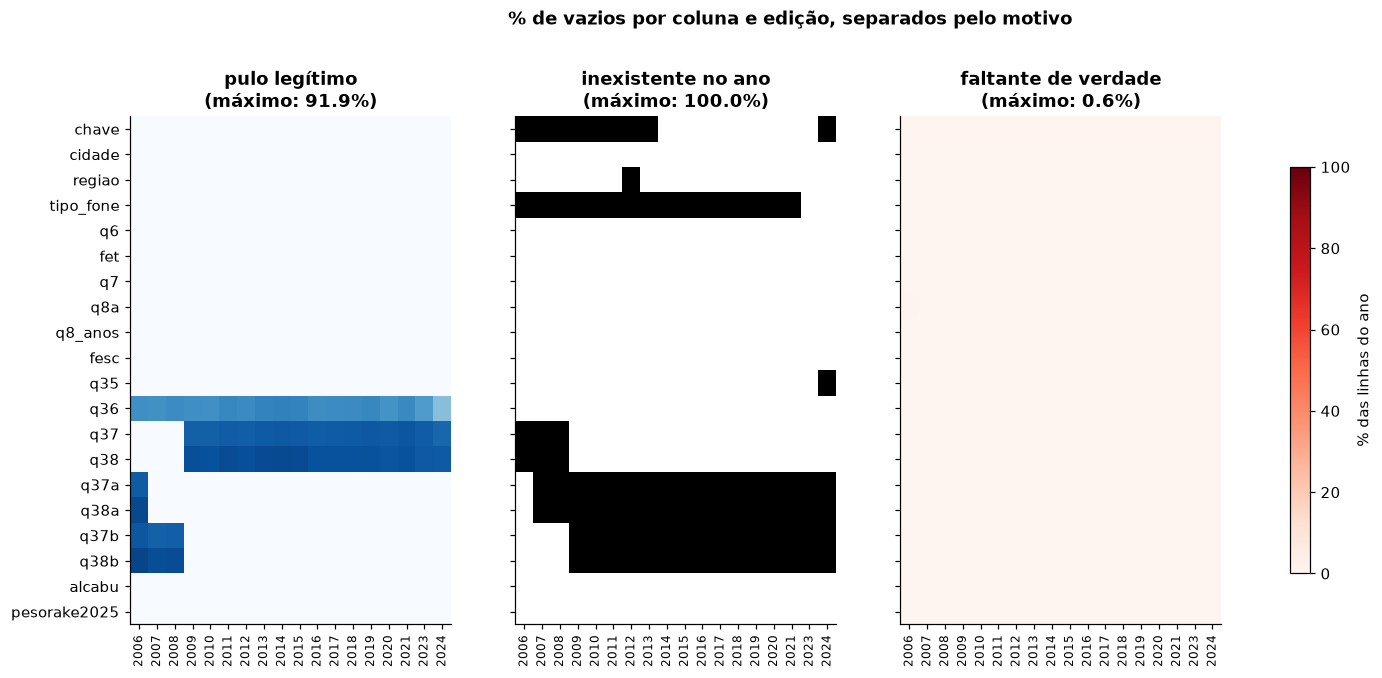

,pulo legítimo,inexistente no ano,faltante de verdade,% faltante de verdade
chave,0,451248,0,0.000
cidade,0,0,0,0.000
regiao,0,45448,0,0.000
tipo_fone,0,784479,0,0.000
q6,0,0,0,0.000
fet,0,0,0,0.000
q7,0,0,0,0.000
q8a,0,0,346,0.042
q8_anos,0,0,0,0.000
fesc,0,0,0,0.000


In [7]:
vazio = bruto == ''
ano_txt = bruto['ano'].astype(str)
sexo_txt = bruto['q7'].astype(str)
q36_txt = bruto['q36'].astype(str)

# Regras de aplicabilidade (True = a pergunta se aplicava ao entrevistado)
bebe_mensal = np.where(ano_txt == '2006', q36_txt.isin(['1', '2', '3', '4']), q36_txt.isin(['1', '2', '3', '4', '5']))
aplica = pd.DataFrame(True, index=bruto.index, columns=bruto.columns)
aplica['q36'] = np.where(ano_txt == '2024', q36_txt != '', bruto['q35'].astype(str) == '1')  # 2024: filtro R502 não publicado
for col, sexo in [('q37', '1'), ('q37a', '1'), ('q38', '2'), ('q38a', '2')]:
    aplica[col] = bebe_mensal & (sexo_txt == sexo)
aplica['q37b'] = bebe_mensal & (sexo_txt == '1') & np.where(ano_txt == '2006', bruto['q37a'].astype(str) == '1', True)
aplica['q38b'] = bebe_mensal & (sexo_txt == '2') & np.where(ano_txt == '2006', bruto['q38a'].astype(str) == '1', True)

inexistente = vazio.groupby(bruto['ano'], observed=True).transform('all')
pulo = vazio & ~aplica & ~inexistente
faltante = vazio & aplica & ~inexistente

categorias = {'pulo legítimo': pulo, 'inexistente no ano': inexistente, 'faltante de verdade': faltante}
mapas = {nome: m.drop(columns=['ano']).groupby(bruto['ano'], observed=True).mean() * 100 for nome, m in categorias.items()}

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, (nome, mapa), cor in zip(axes, mapas.items(), ['Blues', 'Greys', 'Reds']):
    im = ax.imshow(mapa.T.values, aspect='auto', cmap=cor, vmin=0, vmax=100)
    ax.set_xticks(range(len(mapa.index)), mapa.index, rotation=90, fontsize=8)
    ax.set_yticks(range(len(mapa.columns)), mapa.columns)
    ax.set_title(f'{nome}\n(máximo: {mapa.values.max():.1f}%)')
fig.colorbar(im, ax=axes, label='% das linhas do ano', shrink=0.8)
fig.suptitle('% de vazios por coluna e edição, separados pelo motivo', fontweight='bold', y=1.04)
plt.show()

classificacao = pd.DataFrame({nome: m.drop(columns=['ano']).sum() for nome, m in categorias.items()})
classificacao['% faltante de verdade'] = (classificacao['faltante de verdade'] / len(bruto) * 100).round(3)
classificacao

**Leitura:** o preto do mapa da v1 era quase todo azul (pulo) ou cinza (inexistente). O vermelho, de **faltante de verdade, fica praticamente vazio**: só 346 respostas de `q8a`⁷ em 2006 e casos isolados. As sete colunas que respondem às perguntas (`ano`, `cidade`, `fet`¹⁵, `q7`⁶, `fesc`¹⁷, `alcabu`¹⁸, `pesorake2025`¹⁹) têm **0% de vazio em todos os anos**. Os inexistentes contam a história do questionário: as perguntas de doses mudaram de nome (`q37a`⁹/`q38a`¹⁰ só em 2006, `q37b`¹¹/`q38b`¹² em 2006-2008, `q37`¹/`q38`² desde 2009), `tipo_fone` só existe desde 2023, `q35`³ não existe em 2024, `chave` não foi publicada em 2006-2013 e 2024, e `regiao` falta em 2012 (sai de `cidade`).

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

> ⁶ **q7**: registro do questionário, a todos: "Sexo: 1 = masculino, 2 = feminino".

> ⁷ **q8a**: pergunta, a todos: "Até que série e grau o(a) Sr.(a) estudou?". 1 = curso primário, 2 = admissão, 3 = ginasial, 4 = 1º grau ou fundamental, 5 = 2º grau ou ensino médio, 6 = 3º grau ou superior, 7 = pós-graduação, 8 = nunca estudou, 777 = não sabe (só aceito se idade > 60), 888 = não quis responder. 2006 usa outra codificação.

> ⁹ **q37a**: pergunta de 2006, só homens: primeira etapa da pergunta de doses ("> 2 doses", rótulo do dicionário); quem respondeu sim seguiu para q37b. A redação de 2006 não foi publicada no relatório daquele ano.

> ¹⁰ **q38a**: pergunta de 2006, só mulheres: primeira etapa ("> 1 dose", rótulo do dicionário); quem respondeu sim seguiu para q38b. Redação de 2006 não publicada no relatório.

> ¹¹ **q37b**: pergunta de 2006 a 2008, só homens: "Nos últimos 30 dias, o sr chegou a consumir mais do que 5 doses de bebida alcoólica em uma única ocasião?" ("mais do que 5" = 6 ou mais). Questionário Vigitel 2008.

> ¹² **q38b**: pergunta de 2006 a 2008, só mulheres: "... mais do que 4 doses ..." (5 ou mais). Questionário Vigitel 2008.

> ¹⁵ **fet**: variável derivada: faixa etária calculada pelo Ministério a partir de q6. 1 = 18 a 24 (os "jovens"), 2 = 25 a 34, 3 = 35 a 44, 4 = 45 a 54, 5 = 55 a 64, 6 = 65 e mais.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

### 4.2 O que o mapa não mostra

Três riscos ficam escondidos justamente nas células brancas:

1. **Branco pode ser imputação.** `fesc`¹⁷ não tem vazios porque o Ministério imputa a escolaridade de quem respondeu "não sabe" ou "não quis responder" em `q8a`⁷. São cerca de 8 mil casos, 1% da base (seção 10.1). É dado estimado, não declarado.
2. **`alcabu`¹⁸ trata vazio como "não".** Quem não respondeu `q37`¹/`q38`² entra como 0. Isso só é correto se todo vazio for pulo. A seção 11.2 confere a regra em **todos os anos, inclusive 2024**, pela `q36`⁴: ninguém fora do filtro respondeu e ninguém dentro dele ficou sem resposta. O que não dá para separar em 2024 é por que alguém ficou fora do bloco (nunca bebeu, não bebeu em 12 meses ou recusou), porque `R501`¹³ e `R502`¹⁴ não foram publicadas.
3. **Quem não atendeu o telefone não aparece no mapa.** O mapa só cobre quem respondeu à pesquisa. O peso corrige a composição por sexo, idade e escolaridade, mas não diferenças de comportamento entre quem atende e quem não atende. Somado à troca de fixo por celular (seção 8), é o maior risco da comparação 2010 x 2024, e pode ser MNAR (a ausência pode depender do próprio comportamento de beber). Só pode ser declarado, não corrigido.

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

> ⁷ **q8a**: pergunta, a todos: "Até que série e grau o(a) Sr.(a) estudou?". 1 = curso primário, 2 = admissão, 3 = ginasial, 4 = 1º grau ou fundamental, 5 = 2º grau ou ensino médio, 6 = 3º grau ou superior, 7 = pós-graduação, 8 = nunca estudou, 777 = não sabe (só aceito se idade > 60), 888 = não quis responder. 2006 usa outra codificação.

> ¹³ **R501**: pergunta de 2024, a todos: "Na sua vida, o(a) Sr.(a) já consumiu alguma bebida alcoólica?" (não: pula o bloco de álcool). A resposta não foi publicada na base de 2024.

> ¹⁴ **R502**: pergunta de 2024, a quem já bebeu: "Nos últimos 12 meses o(a) Sr.(a) consumiu alguma bebida alcoólica?" (não: pula o bloco). Substitui q35 como filtro de entrada; resposta não publicada na base de 2024.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

## 5. Dicionário do recorte

Os códigos vêm do dicionário oficial (`dicionario-vigitel-2006-2024.xlsx`, aba *Variáveis_Vigitel*) e as redações dos questionários (apêndices dos relatórios). A base de agosto de 2026 foi publicada **sem rótulos**, de propósito, para evitar divergência com o dicionário, então os rótulos vêm daqui. As notas abaixo da tabela trazem a redação de cada pergunta.

| Coluna | Tipo | Classificação (Módulo 2) |
|---|---|---|
| `ano` | controle | Quantitativa discreta (usada como categoria de tempo): 2006 a 2024, sem 2022 |
| `cidade` | controle | Qualitativa nominal: 1 a 27 (26 capitais e Distrito Federal) |
| `q6`⁵ | pergunta | Quantitativa discreta |
| `fet`¹⁵ | derivada | Qualitativa ordinal |
| `q7`⁶ | pergunta | Qualitativa nominal |
| `q8a`⁷ | pergunta | Qualitativa ordinal |
| `q8_anos`¹⁶ | derivada | Quantitativa contínua |
| `fesc`¹⁷ | derivada | Qualitativa ordinal |
| `q35`³ | pergunta | Qualitativa nominal |
| `q36`⁴ | pergunta | Qualitativa ordinal |
| `q37`¹, `q38`² | pergunta | Qualitativa nominal (binária) |
| `q37a`⁹, `q38a`¹⁰, `q37b`¹¹, `q38b`¹² | pergunta (versões antigas) | Qualitativa nominal (binária) |
| `alcabu`¹⁸ | derivada | Qualitativa nominal (binária) |
| `pesorake2025`¹⁹ | derivada | Quantitativa contínua |

Rotina oficial do indicador, na aba *Indicadores_Vigitel*: `gen alcabu = cond(q37==1 | q38==1, 1, 0)`. Como o indicador vale 0 para quem não bebe, **o denominador é toda a população adulta**, e não só quem bebe.

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

> ⁵ **q6**: pergunta, a todos: "Qual sua idade?" (só aceita 18 anos ou mais).

> ⁶ **q7**: registro do questionário, a todos: "Sexo: 1 = masculino, 2 = feminino".

> ⁷ **q8a**: pergunta, a todos: "Até que série e grau o(a) Sr.(a) estudou?". 1 = curso primário, 2 = admissão, 3 = ginasial, 4 = 1º grau ou fundamental, 5 = 2º grau ou ensino médio, 6 = 3º grau ou superior, 7 = pós-graduação, 8 = nunca estudou, 777 = não sabe (só aceito se idade > 60), 888 = não quis responder. 2006 usa outra codificação.

> ⁹ **q37a**: pergunta de 2006, só homens: primeira etapa da pergunta de doses ("> 2 doses", rótulo do dicionário); quem respondeu sim seguiu para q37b. A redação de 2006 não foi publicada no relatório daquele ano.

> ¹⁰ **q38a**: pergunta de 2006, só mulheres: primeira etapa ("> 1 dose", rótulo do dicionário); quem respondeu sim seguiu para q38b. Redação de 2006 não publicada no relatório.

> ¹¹ **q37b**: pergunta de 2006 a 2008, só homens: "Nos últimos 30 dias, o sr chegou a consumir mais do que 5 doses de bebida alcoólica em uma única ocasião?" ("mais do que 5" = 6 ou mais). Questionário Vigitel 2008.

> ¹² **q38b**: pergunta de 2006 a 2008, só mulheres: "... mais do que 4 doses ..." (5 ou mais). Questionário Vigitel 2008.

> ¹⁵ **fet**: variável derivada: faixa etária calculada pelo Ministério a partir de q6. 1 = 18 a 24 (os "jovens"), 2 = 25 a 34, 3 = 35 a 44, 4 = 45 a 54, 5 = 55 a 64, 6 = 65 e mais.

> ¹⁶ **q8_anos**: variável derivada: anos de estudo calculados pelo Ministério combinando q8a e q8b pela tabela do item 2.3 das Orientações (por exemplo, ensino médio completo = 11, superior com 4 anos = 15, pós = 20). Pode ter valores fracionários imputados.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

In [8]:
ROTULOS = {
    'fet': {'1': '18 a 24', '2': '25 a 34', '3': '35 a 44', '4': '45 a 54', '5': '55 a 64', '6': '65 e mais'},
    'q7': {'1': 'masculino', '2': 'feminino'},
    'fesc': {'1': '0 a 8 anos', '2': '9 a 11 anos', '3': '12 anos e mais'},
    'cidade': {str(i): n for i, n in enumerate(
        ['Aracaju', 'Belém', 'Belo Horizonte', 'Boa Vista', 'Campo Grande', 'Cuiabá', 'Curitiba',
         'Florianópolis', 'Fortaleza', 'Goiânia', 'João Pessoa', 'Macapá', 'Maceió', 'Manaus', 'Natal',
         'Palmas', 'Porto Alegre', 'Porto Velho', 'Recife', 'Rio Branco', 'Rio de Janeiro', 'Salvador',
         'São Luís', 'São Paulo', 'Teresina', 'Vitória', 'Distrito Federal'], start=1)},
}

# Tentativa de ler a rotina oficial no próprio dicionário (precisa de openpyxl; se falhar, o texto acima vale)
try:
    dic = pd.read_excel(obter(ARQ_DICIONARIO), sheet_name='Indicadores_Vigitel', header=3)
    display(dic[dic.iloc[:, 0].astype(str).str.strip().eq('alcabu')].iloc[:, [0, 4, 7]])
except Exception as erro:
    print('Dicionário não lido neste ambiente:', erro)

Dicionário não lido neste ambiente: [Errno 13] Permission denied: '..\\..\\dados\\raw\\dicionario-vigitel-2006-2024.xlsx'


## 6. Unidade de observação e chave

Para juntar tabelas no pipeline (modelo estrela), cada entrevistado precisa de um identificador único. A base traz a coluna `chave`.

In [9]:
ch = bruto['chave'].astype(str)
preenchida = ch != ''
print(f'chave vazia: {(~preenchida).sum():,} registros ({(~preenchida).mean():.1%})')
print(f'chave preenchida: {preenchida.sum():,} | valores distintos entre as preenchidas: {ch[preenchida].nunique():,}')
print(f'registros com chave repetida (preenchida): {ch[preenchida].duplicated(keep=False).sum():,}')
pd.crosstab(bruto['ano'], np.where(preenchida, 'preenchida', 'vazia'))

chave vazia: 451,248 registros (54.2%)


chave preenchida: 381,969 | valores distintos entre as preenchidas: 295,968


registros com chave repetida (preenchida): 147,263


col_0,preenchida,vazia
ano,,
2006,0,54369
2007,0,54251
2008,0,54353
2009,0,54367
2010,0,54339
2011,0,54144
2012,0,45448
2013,0,52929
2014,40853,0


**Leitura:** `chave` só existe de 2014 a 2023 e, mesmo nesses anos, se repete. Não serve como identificador do entrevistado; o pipeline precisará de uma chave substituta (decisão D10).

## 7. Cobertura temporal e tamanho da amostra

A pergunta compara 2010 com o ano mais recente. O tamanho da amostra de cada recorte (jovens, jovens por escolaridade, jovens por capital) define o que dá para responder com precisão.

In [10]:
explo = pd.DataFrame({
    'ano': bruto['ano'].astype(int),
    'cidade': bruto['cidade'].astype(str).map(ROTULOS['cidade']),
    'idade': pd.to_numeric(bruto['q6'].astype(str)),
    'fet': bruto['fet'].astype(str),
    'sexo': bruto['q7'].astype(str).map(ROTULOS['q7']),
    'fesc': bruto['fesc'].astype(str).map(ROTULOS['fesc']),
    'anos_estudo': pd.to_numeric(bruto['q8_anos'].astype(str), errors='coerce'),
    'alcabu': pd.to_numeric(bruto['alcabu'].astype(str)),
    'peso': pd.to_numeric(bruto['pesorake2025']),
    'fone': bruto['tipo_fone'].astype(str).replace('', '(vazio)'),
})
jovem = explo['fet'] == '1'
ANOS = sorted(int(a) for a in explo['ano'].unique())
print('Edições:', ANOS)
print('Edições ausentes entre 2006 e 2024:', sorted(set(range(2006, 2025)) - set(ANOS)))


def prevalencia(df, por):
    """Prevalência ponderada de alcabu com IC 95% aproximado pelo n efetivo de Kish."""
    g = df.assign(wy=df['peso'] * df['alcabu'], w2=df['peso'] ** 2)
    r = g.groupby(por, observed=True).agg(n=('alcabu', 'size'), soma_w=('peso', 'sum'),
                                          soma_wy=('wy', 'sum'), soma_w2=('w2', 'sum')).reset_index()
    r['prev'] = r['soma_wy'] / r['soma_w'] * 100
    r['n_efetivo'] = r['soma_w'] ** 2 / r['soma_w2']
    ep = np.sqrt(r['prev'] / 100 * (1 - r['prev'] / 100) / r['n_efetivo']) * 100
    r['ic95_inf'], r['ic95_sup'] = r['prev'] - 1.96 * ep, r['prev'] + 1.96 * ep
    return r.drop(columns=['soma_w', 'soma_wy', 'soma_w2'])


amostra = pd.DataFrame({
    'entrevistas': explo.groupby('ano').size(),
    '18 a 24': explo[jovem].groupby('ano').size(),
    '35 a 44': explo[explo['fet'] == '3'].groupby('ano').size(),
})
amostra['% jovens na amostra'] = (amostra['18 a 24'] / amostra['entrevistas'] * 100).round(1)
amostra

Edições: [2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2023, 2024]
Edições ausentes entre 2006 e 2024: [2022]


,entrevistas,18 a 24,35 a 44,% jovens na amostra
ano,,,,
2006,54369,8770,12158,16.1
2007,54251,8432,12058,15.5
2008,54353,8036,11677,14.8
2009,54367,7760,11369,14.3
2010,54339,7364,10902,13.6
2011,54144,6971,10436,12.9
2012,45448,5353,8580,11.8
2013,52929,5834,9069,11.0
2014,40853,4316,7054,10.6


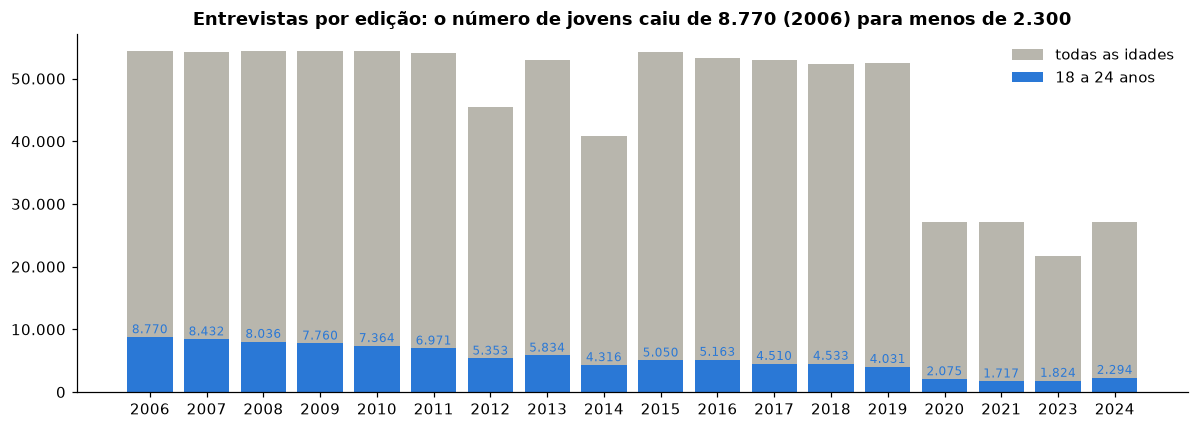

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(amostra))
ax.bar(x, amostra['entrevistas'], color=COR_OUTROS, label='todas as idades')
ax.bar(x, amostra['18 a 24'], color=COR_JOVEM, label='18 a 24 anos')
for xi, v in zip(x, amostra['18 a 24']):
    ax.text(xi, v + 600, f'{v:,}'.replace(',', '.'), ha='center', fontsize=8, color=COR_JOVEM)
ax.set_xticks(x, amostra.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.set_title('Entrevistas por edição: o número de jovens caiu de 8.770 (2006) para menos de 2.300')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 7.1 Células das perguntas P2 e P5

Quantos jovens há em cada faixa de escolaridade (P2) e em cada capital (P5), nos anos das comparações.

In [12]:
celulas_p2 = pd.crosstab(explo.loc[jovem, 'ano'], explo.loc[jovem, 'fesc'])[list(CORES_ESC)]
display(celulas_p2)

celulas_p5 = pd.crosstab(explo.loc[jovem, 'cidade'], explo.loc[jovem, 'ano'])
print('Jovens por capital: resumo por edição (mínimo, mediana, máximo)')
display(celulas_p5.agg(['min', 'median', 'max']).astype(int))
print('Capitais com menos de 100 jovens entrevistados em 2024:', (celulas_p5[2024] < 100).sum(), 'de 27')
print('Menores amostras de 2024:', celulas_p5[2024].nsmallest(5).to_dict())

fesc,0 a 8 anos,9 a 11 anos,12 anos e mais
ano,,,
2006,1042,4867,2861
2007,864,4865,2703
2008,767,4441,2828
2009,628,4236,2896
2010,610,3847,2907
2011,592,3770,2609
2012,446,2778,2129
2013,385,3000,2449
2014,286,2271,1759


Jovens por capital: resumo por edição (mínimo, mediana, máximo)


ano,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024
min,221,213,200,189,179,170,114,141,91,105,99,90,90,94,33,32,47,53
median,325,306,305,287,270,255,195,214,154,180,190,165,164,142,73,60,68,84
max,433,410,400,381,391,338,278,305,235,281,318,298,251,209,133,112,102,133


Capitais com menos de 100 jovens entrevistados em 2024: 20 de 27
Menores amostras de 2024: {'Florianópolis': 53, 'Porto Alegre': 57, 'Fortaleza': 60, 'São Paulo': 62, 'Curitiba': 65}


## 8. Modo de coleta: telefone fixo e celular

In [13]:
pd.crosstab(explo['ano'], explo['fone'], margins=True)

fone,(vazio),CELULAR,FIXO,All
ano,,,,
2006,54369,0,0,54369
2007,54251,0,0,54251
2008,54353,0,0,54353
2009,54367,0,0,54367
2010,54339,0,0,54339
2011,54144,0,0,54144
2012,45448,0,0,45448
2013,52929,0,0,52929
2014,40853,0,0,40853


**Leitura:** até 2021 o Vigitel entrevistou **só por telefone fixo**; a coluna `tipo_fone` vem vazia porque não havia o que distinguir. Em 2023 metade das entrevistas foi por celular e em 2024 mais de 90%.

### 8.1 Por que a troca é uma limitação

O problema não é o celular ser pior. É que **2010 e 2024 entrevistaram públicos diferentes, de formas diferentes**, e a diferença entre os anos mistura mudança de comportamento com mudança de método:

1. **Quem é alcançado.** Em 2010 só entravam casas com linha fixa. O jovem com fixo em 2010 era, em geral, quem morava com os pais numa casa mais estruturada; quem morava sozinho, em república ou em casa sem linha fixa ficava de fora. Em 2024 o celular alcança quase todos. O "jovem de 2010" e o "jovem de 2024" do Vigitel não são o mesmo recorte.
2. **Como a pessoa responde.** No fixo de casa, com a família por perto, é constrangedor dizer que bebeu muito, e a tendência é declarar menos (viés de desejabilidade social). No celular a pessoa fala sozinha.
3. **O peso não corrige isso.** `pesorake2025`¹⁹ ajusta sexo, idade, escolaridade e capital. Ele não sabe se quem tem fixo bebe diferente de quem não tem, nem corrige o constrangimento.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

### 8.2 Evidência: 2023, metade por fixo e metade por celular

In [14]:
modo = explo[explo['ano'].isin([2023, 2024])].copy()
modo['grupo'] = np.where(modo['fet'] == '1', '18 a 24', 'todas as idades')
prev_modo = pd.concat([prevalencia(modo, ['ano', 'fone']).assign(grupo='todas as idades'),
                       prevalencia(modo[modo['fet'] == '1'], ['ano', 'fone']).assign(grupo='18 a 24')])
prev_modo['prevalência (IC 95%)'] = prev_modo.apply(
    lambda r: f"{r['prev']:.1f}% ({r['ic95_inf']:.1f} a {r['ic95_sup']:.1f}) n={r['n']:,}", axis=1)
display(prev_modo.pivot(index=['grupo', 'ano'], columns='fone', values='prevalência (IC 95%)'))

print('Composição de cada modo por faixa etária (% das entrevistas, sem peso)')
comp_idade = pd.crosstab([modo['ano'], modo['fone']], modo['fet'].map(ROTULOS['fet']), normalize='index').mul(100).round(1)
display(comp_idade)
print('Composição de cada modo por escolaridade (% das entrevistas, sem peso)')
display(pd.crosstab([modo['ano'], modo['fone']], modo['fesc'], normalize='index')[list(CORES_ESC)].mul(100).round(1))

fone                                       CELULAR                          FIXO
grupo           ano                                                             
18 a 24         2023   25.7% (20.9 a 30.5) n=1,232     19.5% (14.0 a 25.1) n=592
                2024   24.8% (21.3 a 28.2) n=2,187      10.5% (2.4 a 18.7) n=107
todas as idades 2023  27.0% (25.4 a 28.7) n=10,832  15.5% (14.2 a 16.9) n=10,858
                2024  23.2% (22.3 a 24.2) n=24,448    11.7% (9.6 a 13.8) n=2,600

Composição de cada modo por faixa etária (% das entrevistas, sem peso)


fet           18 a 24  25 a 34  35 a 44  45 a 54  55 a 64  65 e mais
ano  fone                                                           
2023 CELULAR     11.4     21.6     24.7     19.5     14.2        8.6
     FIXO         5.5      8.1     12.8     15.9     19.6       38.2
2024 CELULAR      8.9     20.5     25.1     21.4     14.7        9.4
     FIXO         4.1      6.2     10.7     15.2     20.0       43.8

Composição de cada modo por escolaridade (% das entrevistas, sem peso)


fesc          0 a 8 anos  9 a 11 anos  12 anos e mais
ano  fone                                            
2023 CELULAR        23.2         40.4            36.4
     FIXO           27.7         34.3            38.0
2024 CELULAR        20.0         39.9            40.1
     FIXO           23.4         35.0            41.7

**Leitura:** no mesmo ano, quem respondeu pelo celular declarou muito mais consumo abusivo. Em 2023: 27,0% contra 15,5% em todas as idades, e 25,7% contra 19,5% entre os jovens. Parte disso é composição (o fixo tem muito mais idosos, que bebem menos), mas a diferença também aparece dentro da faixa jovem. Não dá para saber quanto é "outro tipo de pessoa" e quanto é "resposta mais sincera"; para a comparação no tempo o efeito é o mesmo: **2024 (90% celular) tende a sair mais alto que 2010 (100% fixo) só por causa do método.**

Ressalva técnica: o peso é calibrado para a amostra total de cada ano, e não para cada modo separadamente, então a comparação é indicativa. O fixo de 2024 tem só cerca de 100 jovens, e o intervalo é muito largo.

**Consequências para a leitura da prévia (seção 13):**
- a comparação 2010 x 2024 mistura comportamento e método; a parte de 2024 que vem do método tende a ser para cima;
- a alta das outras faixas e das mulheres em 2023-2024 pode ter parte artificial; a alta das jovens mulheres resiste melhor, porque já era visível em 2019, ainda só com fixo;
- a queda dos jovens homens aparece só em 2024 e é a mais exposta a esse efeito;
- por isso a decisão D2 inclui 2019 (último ano só com fixo) como comparação de sensibilidade. Ela é feita na seção 13.1.

## 9. Idade e faixa etária

In [15]:
faixa_recalc = pd.cut(explo['idade'], [17, 24, 34, 44, 54, 64, 200], labels=list('123456')).astype(str)
print('Registros em que fet não bate com a idade:', (faixa_recalc != explo['fet']).sum())
print('Idade mínima:', explo['idade'].min(), '| máxima:', explo['idade'].max())
print('Registros com idade acima de 100 anos:', (explo['idade'] > 100).sum())
print('\nIdades dos jovens: distribuição em 2010 e 2024 (% dentro do ano)')
pd.crosstab(explo.loc[jovem, 'idade'], explo.loc[jovem, 'ano'], normalize='columns')[[2010, 2024]].mul(100).round(1).T

Registros em que fet não bate com a idade: 0
Idade mínima: 18 | máxima: 120
Registros com idade acima de 100 anos: 46

Idades dos jovens: distribuição em 2010 e 2024 (% dentro do ano)


idade,18,19,20,21,22,23,24
ano,,,,,,,
2010,14.8,13.2,14.6,14.0,15.6,14.0,13.8
2024,12.5,11.9,14.1,13.1,15.9,15.7,16.8


**Leitura:** `fet`¹⁵ é coerente com `q6`⁵ em todos os registros, então não há o que recalcular. Idades acima de 100 anos não afetam as perguntas, que só usam 18-24 e 35-44.

> ⁵ **q6**: pergunta, a todos: "Qual sua idade?" (só aceita 18 anos ou mais).

> ¹⁵ **fet**: variável derivada: faixa etária calculada pelo Ministério a partir de q6. 1 = 18 a 24 (os "jovens"), 2 = 25 a 34, 3 = 35 a 44, 4 = 45 a 54, 5 = 55 a 64, 6 = 65 e mais.

## 10. Escolaridade: a proxy de classe social

### 10.1 Coerência entre `q8a`⁷, `q8_anos`¹⁶ e `fesc`¹⁷

> ⁷ **q8a**: pergunta, a todos: "Até que série e grau o(a) Sr.(a) estudou?". 1 = curso primário, 2 = admissão, 3 = ginasial, 4 = 1º grau ou fundamental, 5 = 2º grau ou ensino médio, 6 = 3º grau ou superior, 7 = pós-graduação, 8 = nunca estudou, 777 = não sabe (só aceito se idade > 60), 888 = não quis responder. 2006 usa outra codificação.

> ¹⁶ **q8_anos**: variável derivada: anos de estudo calculados pelo Ministério combinando q8a e q8b pela tabela do item 2.3 das Orientações (por exemplo, ensino médio completo = 11, superior com 4 anos = 15, pós = 20). Pode ter valores fracionários imputados.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

In [16]:
fesc_recalc = pd.cut(explo['anos_estudo'], [-1, 8.999, 11.999, 99], labels=list(CORES_ESC)).astype(str)
print('fesc diferente da faixa recalculada pelos anos de estudo:', (fesc_recalc != explo['fesc']).sum())
print('q8a com 777 (não sabe) ou 888 (não quis responder):',
      bruto['q8a'].isin(['777', '888']).sum(), '| q8a vazia:', (bruto['q8a'] == '').sum())
print('...e mesmo assim fesc vazia:', (bruto['fesc'] == '').sum(), '(o Ministério imputa a escolaridade)')
print('\nCódigos de q8a por edição (2006 usa outra codificação):')
pd.crosstab(bruto['ano'], bruto['q8a'])

fesc diferente da faixa recalculada pelos anos de estudo: 0
q8a com 777 (não sabe) ou 888 (não quis responder): 8170 | q8a vazia: 346
...e mesmo assim fesc vazia: 0 (o Ministério imputa a escolaridade)

Códigos de q8a por edição (2006 usa outra codificação):


q8a,,1,2,3,4,5,6,7,8,9,10,777,888
ano,,,,,,,,,,,,,
2006,346,5477,2290,7906,20268,69,204,13919,2351,1489,50,0,0
2007,0,4177,111,735,9648,21121,14036,2762,1430,0,0,152,79
2008,0,3550,95,744,10051,21164,14662,2560,1321,0,0,109,97
2009,0,3007,91,1097,9466,21133,15358,2743,1216,0,0,124,132
2010,0,2926,99,772,9987,20795,15574,2812,1075,0,0,134,165
2011,0,3674,128,887,9718,20587,14670,2875,1175,0,0,178,252
2012,0,2366,64,909,8299,17552,12479,2472,918,0,0,200,189
2013,0,3352,135,1232,8655,19293,14953,3412,1146,0,0,246,505
2014,0,2652,116,865,7173,15286,10357,2952,931,0,0,181,340


**Leitura:** `fesc`¹⁷ não tem vazios, mesmo havendo 8.170 `q8a`⁷ = 777 ou 888: a faixa de escolaridade é **imputada** pelo Ministério, porque entra no cálculo do peso. Em 2006 `q8a`⁷ usa outra codificação (aparecem os códigos 9 e 10 e a distribuição é diferente). Isso não afeta a análise se ela usar `fesc`¹⁷ e começar em 2010. `fesc`¹⁷ bate com a faixa recalculada a partir de `q8_anos`¹⁶ em 100% dos registros.

> ⁷ **q8a**: pergunta, a todos: "Até que série e grau o(a) Sr.(a) estudou?". 1 = curso primário, 2 = admissão, 3 = ginasial, 4 = 1º grau ou fundamental, 5 = 2º grau ou ensino médio, 6 = 3º grau ou superior, 7 = pós-graduação, 8 = nunca estudou, 777 = não sabe (só aceito se idade > 60), 888 = não quis responder. 2006 usa outra codificação.

> ¹⁶ **q8_anos**: variável derivada: anos de estudo calculados pelo Ministério combinando q8a e q8b pela tabela do item 2.3 das Orientações (por exemplo, ensino médio completo = 11, superior com 4 anos = 15, pós = 20). Pode ter valores fracionários imputados.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

### 10.2 Tabela de frequência da escolaridade dos jovens (Módulo 2: fi, fr, Fac, Frac)

A tabela é feita **sem peso** (descreve a amostra) e **com peso** (estima a população). A diferença entre as duas mostra o quanto a amostra se afasta da população e por que o peso é obrigatório.

In [17]:
def tabela_frequencia(serie, pesos=None, ordem=None):
    contagem = (serie.value_counts() if pesos is None else pesos.groupby(serie, observed=True).sum())
    contagem = contagem.reindex(ordem) if ordem else contagem
    t = pd.DataFrame({'fi': contagem})
    t['fr (%)'] = t['fi'] / t['fi'].sum() * 100
    t['Fac'] = t['fi'].cumsum()
    t['Frac (%)'] = t['fr (%)'].cumsum()
    return t


for ano in (2010, 2024):
    sel = jovem & (explo['ano'] == ano)
    sem = tabela_frequencia(explo.loc[sel, 'fesc'], ordem=list(CORES_ESC))
    com = tabela_frequencia(explo.loc[sel, 'fesc'], explo.loc[sel, 'peso'], ordem=list(CORES_ESC))
    print(f'Jovens de 18 a 24 anos, {ano}')
    display(pd.concat({'amostra (sem peso)': sem.round(1), 'população (com peso)': com[['fr (%)', 'Frac (%)']].round(1)}, axis=1))

Jovens de 18 a 24 anos, 2010


amostra (sem peso)                       população (com peso)         
                               fi fr (%)   Fac Frac (%)               fr (%) Frac (%)
fesc                                                                                 
0 a 8 anos                    610    8.3   610      8.3                 14.4     14.4
9 a 11 anos                  3847   52.2  4457     60.5                 54.4     68.8
12 anos e mais               2907   39.5  7364    100.0                 31.2    100.0

Jovens de 18 a 24 anos, 2024


amostra (sem peso)                       população (com peso)         
                               fi fr (%)   Fac Frac (%)               fr (%) Frac (%)
fesc                                                                                 
0 a 8 anos                    131    5.7   131      5.7                  8.3      8.3
9 a 11 anos                  1407   61.3  1538     67.0                 58.7     67.0
12 anos e mais                756   33.0  2294    100.0                 33.0    100.0

**Leitura:** a composição dos jovens por escolaridade **mudou entre 2010 e 2024**: na população (com peso), a faixa de 0 a 8 anos caiu de 14,4% para 8,3% e a de 9 a 11 anos subiu de 54,4% para 58,7%. A amostra sem peso tem jovens de alta escolaridade a mais (39,5% contra 31,2% em 2010), o que confirma que proporção sem peso não representa a população. Para P2 isso importa: se a prevalência geral dos jovens muda, parte da mudança pode vir só de haver mais jovens numa faixa (efeito composição). Por isso a P2 deve ser respondida **dentro de cada faixa**.

## 11. A medida de consumo

### 11.1 A pergunta de entrada (`q35`³) mudou de codificação e saiu em 2024

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

In [18]:
pd.crosstab(bruto['ano'], bruto['q35'])

q35,1,2,3,4,888,
ano,,,,,,
2006,19963,1128,28869,4409,0,0
2007,20324,33927,0,0,0,0
2008,19287,35066,0,0,0,0
2009,19837,34530,0,0,0,0
2010,20058,34281,0,0,0,0
2011,18176,35968,0,0,0,0
2012,15954,29494,0,0,0,0
2013,17154,35775,0,0,0,0
2014,12786,28062,0,0,5,0


**Leitura:** a codificação de `q35`³ mudou ao longo da série (2006 tinha 4 opções; de 2007 a 2019, 2; de 2020 em diante, 3 mais "não quis informar"). Em 2024 a pergunta **não existe**: o questionário de 2024 a substituiu por duas perguntas, `R501`¹³ (já bebeu na vida?) e `R502`¹⁴ (bebeu nos últimos 12 meses?), cujas respostas não foram publicadas. Também há divergência de rótulos: o dicionário chama o código 2 de "sim, mas não no último mês", mas o questionário de 2023 traz 2 = "não" e 3 = "nunca". Qualquer indicador de "bebe ou não bebe" com `q35`³ não seria comparável entre 2010 e 2024; o `alcabu`¹⁸ não depende de `q35`³.

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

> ¹³ **R501**: pergunta de 2024, a todos: "Na sua vida, o(a) Sr.(a) já consumiu alguma bebida alcoólica?" (não: pula o bloco de álcool). A resposta não foi publicada na base de 2024.

> ¹⁴ **R502**: pergunta de 2024, a quem já bebeu: "Nos últimos 12 meses o(a) Sr.(a) consumiu alguma bebida alcoólica?" (não: pula o bloco). Substitui q35 como filtro de entrada; resposta não publicada na base de 2024.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

### 11.2 Quem responde `q37`¹ e `q38`²: o pulo confere em todos os anos

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

In [19]:
respondeu = (bruto[['q37', 'q38', 'q37a', 'q38a', 'q37b', 'q38b']] != '').any(axis=1)
elegivel = pd.Series(bebe_mensal, index=bruto.index)
conferencia = pd.DataFrame({
    'elegíveis (bebe ao menos 1x por mês)': elegivel.groupby(explo['ano']).sum(),
    'elegíveis que responderam (%)': (respondeu[elegivel].groupby(explo.loc[elegivel, 'ano']).mean() * 100).round(2),
    'não elegíveis que responderam': (respondeu & ~elegivel).groupby(explo['ano']).sum(),
})
display(conferencia)

quem = pd.DataFrame({'q37 preenchida': bruto['q37'] != '', 'q38 preenchida': bruto['q38'] != '',
                     'sexo': explo['sexo']})[explo['ano'] >= 2009]
pd.crosstab(quem['sexo'], [quem['q37 preenchida'], quem['q38 preenchida']])

,elegíveis (bebe ao menos 1x por mês),elegíveis que responderam (%),não elegíveis que responderam
ano,,,
2006,14278,100.0,0
2007,16358,100.0,0
2008,15864,100.0,0
2009,16702,100.0,0
2010,16969,100.0,0
2011,15406,100.0,0
2012,13361,100.0,0
2013,14445,100.0,0
2014,10693,100.0,0


q37 preenchida   False          True 
q38 preenchida   False  True    False
sexo                                 
feminino        334470  82480       0
masculino       139022      0  114272

**Leitura:** em todas as edições, 100% de quem bebe pelo menos uma vez por mês respondeu a pergunta de doses, e ninguém fora desse filtro respondeu. `q37`¹ só é perguntada a homens e `q38`² só a mulheres, nunca as duas à mesma pessoa. Portanto o vazio de `q37`¹/`q38`² é **pulo de questionário**, e tratá-lo como "não" no `alcabu`¹⁸ é correto, inclusive em 2024. Quem bebe menos de uma vez por mês (`q36`⁴ = 6) pula as perguntas de doses e entra no `alcabu`¹⁸ como 0, em todos os anos.

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

### 11.3 A pergunta de doses mudou de redação em 2010

In [20]:
uso = pd.DataFrame({c: (bruto[c] != '').groupby(bruto['ano'], observed=True).sum()
                    for c in ['q37a', 'q38a', 'q37b', 'q38b', 'q37', 'q38']})
uso['redação (questionário)'] = np.select(
    [uso.index.astype(int) <= 2008, uso.index.astype(int) == 2009],
    ['mais do que 5 (homem) / 4 (mulher)', 'mais do que 5 / 4 (já na coluna q37/q38)'],
    default='5 ou mais (homem) / 4 ou mais (mulher)')
uso

,q37a,q38a,q37b,q38b,q37,q38,redação (questionário)
ano,,,,,,,
2006,9177,5101,8234,4406,0,0,mais do que 5 (homem) / 4 (mulher)
2007,0,0,10211,6147,0,0,mais do que 5 (homem) / 4 (mulher)
2008,0,0,9777,6087,0,0,mais do que 5 (homem) / 4 (mulher)
2009,0,0,0,0,10157,6545,mais do que 5 / 4 (já na coluna q37/q38)
2010,0,0,0,0,10023,6946,5 ou mais (homem) / 4 ou mais (mulher)
2011,0,0,0,0,9450,5956,5 ou mais (homem) / 4 ou mais (mulher)
2012,0,0,0,0,8029,5332,5 ou mais (homem) / 4 ou mais (mulher)
2013,0,0,0,0,8717,5728,5 ou mais (homem) / 4 ou mais (mulher)
2014,0,0,0,0,6495,4198,5 ou mais (homem) / 4 ou mais (mulher)


**Leitura:** os questionários dos relatórios mostram a mudança que a base esconde:

| Edições | Coluna na base | Redação | Limite real |
|---|---|---|---|
| 2006-2008 | `q37b`¹¹, `q38b`¹² | "mais do que 5 doses" (homem) / "mais do que 4" (mulher) | 6+ / 5+ |
| 2009 | `q37`¹, `q38`² | "mais do que 5 doses" / "mais do que 4" | 6+ / 5+ |
| 2010-2024 | `q37`¹, `q38`² | "cinco ou mais doses" / "quatro ou mais" | 5+ / 4+ |

As *Orientações* (item 3.3) dizem que a redação mudou **a partir de 2010**, e o questionário de 2009 confirma: 2009 ainda usava "mais do que". A base, porém, já guarda 2009 na coluna nova. Consequências: (1) **2010 é o primeiro ano com a pergunta atual**, o que sustenta a escolha do README; (2) 2009 não é comparável com 2010 em diante, mesmo estando na mesma coluna, então uma comparação por triênio não pode juntar 2009 a 2010-2011 (decisão D3); (3) o salto de 2006-2009 para 2010 na série histórica pode ter parte artificial, porque o limite baixou uma dose.

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ¹¹ **q37b**: pergunta de 2006 a 2008, só homens: "Nos últimos 30 dias, o sr chegou a consumir mais do que 5 doses de bebida alcoólica em uma única ocasião?" ("mais do que 5" = 6 ou mais). Questionário Vigitel 2008.

> ¹² **q38b**: pergunta de 2006 a 2008, só mulheres: "... mais do que 4 doses ..." (5 ou mais). Questionário Vigitel 2008.

### 11.4 O `alcabu`¹⁸ oficial pode ser reproduzido?

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

In [21]:
sim = lambda c: bruto[c].astype(str) == '1'
reconstruido = (sim('q37') | sim('q38') | sim('q37b') | sim('q38b')).astype(int)
confere = reconstruido == explo['alcabu']
print(f'alcabu oficial = (q37 ou q38 ou q37b ou q38b igual a 1) em {confere.mean():.4%} dos registros')
print('Divergências:', (~confere).sum())
so_oficial = ((sim('q37') | sim('q38')).astype(int) == explo['alcabu'])
print('Usando só q37 e q38 (rotina do dicionário), divergências por edição:')
print((~so_oficial).groupby(explo['ano']).sum().to_dict())

alcabu oficial = (q37 ou q38 ou q37b ou q38b igual a 1) em 100.0000% dos registros
Divergências: 0
Usando só q37 e q38 (rotina do dicionário), divergências por edição:
{2006: 8094, 2007: 8828, 2008: 8781, 2009: 0, 2010: 0, 2011: 0, 2012: 0, 2013: 0, 2014: 0, 2015: 0, 2016: 0, 2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 0, 2023: 0, 2024: 0}


**Leitura:** o `alcabu`¹⁸ publicado é reproduzido em 100% dos registros quando se juntam os dois pares de colunas. A rotina literal do dicionário (só `q37`¹/`q38`²) reproduz o indicador de 2009 em diante, mas daria zero para todos em 2006-2008. Como a análise começa em 2010, as duas formas dão o mesmo resultado no período de interesse.

> ¹ **q37**: pergunta, só homens: "Nos últimos 30 dias, o Sr. chegou a consumir cinco ou mais doses de bebida alcoólica em uma única ocasião? (cinco doses de bebida alcoólica seriam cinco latas de cerveja, cinco taças de vinho ou cinco doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Feita só a quem bebe pelo menos uma vez por mês (q36 de 1 a 5). Redação "cinco ou mais" desde 2010; em 2009 a mesma coluna guarda a redação antiga, "mais do que 5 doses" (questionários Vigitel 2009, 2010 e 2006-2024).

> ² **q38**: pergunta, só mulheres: "Nos últimos 30 dias, a Sra. chegou a consumir quatro ou mais doses de bebida alcoólica em uma única ocasião? (quatro doses de bebida alcoólica seriam quatro latas de cerveja, quatro taças de vinho ou quatro doses de cachaça, whisky ou qualquer outra bebida alcoólica destilada)". 1 = sim, 2 = não. Mesmo filtro e mesma mudança de redação de q37 ("mais do que 4 doses" em 2009).

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

### 11.5 Em 2024 o filtro de entrada do bloco de álcool mudou

Até 2023, só entrava no bloco de álcool quem dizia que **costuma** beber (`q35`³). Em 2024 entra quem **bebeu nos últimos 12 meses** (`R502`¹⁴), um filtro mais largo. A distribuição de `q36`⁴ entre todos os adultos mostra o efeito.

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

> ¹⁴ **R502**: pergunta de 2024, a quem já bebeu: "Nos últimos 12 meses o(a) Sr.(a) consumiu alguma bebida alcoólica?" (não: pula o bloco). Substitui q35 como filtro de entrada; resposta não publicada na base de 2024.

In [22]:
freq = pd.crosstab(explo['ano'], q36_txt.replace('', 'fora do bloco'), normalize='index').mul(100).round(1)
freq = freq[['1', '2', '3', '4', '5', '6', 'fora do bloco']]
freq.columns = ['1-2 dias/sem', '3-4 dias/sem', '5-6 dias/sem', 'todo dia', '< 1 dia/sem', '< 1 dia/mês', 'fora do bloco']
freq.loc[[2010, 2019, 2021, 2023, 2024]]

,1-2 dias/sem,3-4 dias/sem,5-6 dias/sem,todo dia,< 1 dia/sem,< 1 dia/mês,fora do bloco
ano,,,,,,,
2010,20.6,3.5,0.6,1.3,5.2,5.7,63.1
2019,16.9,3.2,0.6,1.3,6.6,5.4,66.1
2021,17.0,3.1,0.5,1.3,5.5,7.1,65.4
2023,20.1,3.5,0.7,1.3,7.4,8.6,58.4
2024,21.4,3.9,0.8,1.2,10.1,19.8,42.7


**Leitura:** em 2024 a parte da população **fora** do bloco de álcool caiu de 58,4% (2023) para 42,7%. Quase toda a diferença foi para as frequências baixas: "menos de 1 dia por mês" passou de 8,6% para 19,8%, e "menos de 1 dia por semana", de 7,4% para 10,1%. Quem bebe menos de uma vez por mês continua pulando a pergunta de doses, mas quem bebe "menos de 1 dia por semana" agora entra com mais frequência e pode responder sim. É mais uma mudança de método concentrada em 2024, na mesma direção da troca para o celular: tende a elevar o `alcabu`¹⁸ de 2024 em relação a 2010. Fica registrada como decisão D13.

> ¹⁸ **alcabu**: variável derivada: indicador oficial de consumo abusivo, chamado "consumo episódico pesado" desde 2024. 1 se q37 = 1 ou q38 = 1 (em 2006-2008, q37b ou q38b); 0 nos demais casos, inclusive para quem não bebe ou bebe menos de uma vez por mês. O denominador é toda a população adulta. Rotina do dicionário oficial.

## 12. Pesos amostrais (`pesorake2025`¹⁹)

**O que é o peso.** É quantas pessoas da população cada entrevistado representa. Se uma entrevista tem peso 250, aquela resposta "vale" por 250 adultos da sua capital. É assim que cerca de 50 mil entrevistas por ano viram uma estimativa para todos os adultos das capitais.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

In [23]:
pesos = explo.groupby('ano')['peso'].agg(['count', 'min', 'median', 'mean', 'max', 'sum'])
pesos['soma / entrevistas'] = pesos['sum'] / pesos['count']
pesos['max / min'] = pesos['max'] / pesos['min']
pesos['n efetivo (Kish)'] = explo.groupby('ano')['peso'].apply(lambda w: w.sum() ** 2 / (w ** 2).sum())
pesos['n efetivo / n'] = pesos['n efetivo (Kish)'] / pesos['count']
pesos.style.format({'min': '{:,.1f}', 'median': '{:,.0f}', 'mean': '{:,.0f}', 'max': '{:,.0f}', 'sum': '{:,.3e}',
                    'soma / entrevistas': '{:,.0f}', 'max / min': '{:,.0f}', 'n efetivo (Kish)': '{:,.0f}',
                    'n efetivo / n': '{:.2f}'})

,count,min,median,mean,max,sum,soma / entrevistas,max / min,n efetivo (Kish),n efetivo / n
ano,,,,,,,,,,
2006,54369,3.1,244,553,"20,668",3.005e+07,553,"6,676","12,979",0.24
2007,54251,1.9,257,586,"23,633",3.178e+07,586,"12,186","12,986",0.24
2008,54353,1.7,256,589,"21,517",3.199e+07,589,"12,496","13,039",0.24
2009,54367,2.4,254,598,"30,710",3.249e+07,598,"12,655","12,217",0.22
2010,54339,"30,826.6","537,471","1,216,878","33,644,360",6.612e+10,"1,216,878","1,091","12,910",0.24
2011,54144,"31,654.1","566,350","1,235,662","33,797,688",6.690e+10,"1,235,662","1,068","13,691",0.25
2012,45448,"32,523.0","556,376","1,253,864","33,962,216",5.699e+10,"1,253,864","1,044","11,067",0.24
2013,52929,"33,435.5","531,876","1,252,109","34,138,180",6.627e+10,"1,252,109","1,021","12,787",0.24
2014,40853,"34,394.2","532,749","1,257,792","34,325,824",5.138e+10,"1,257,792",998,"9,843",0.24


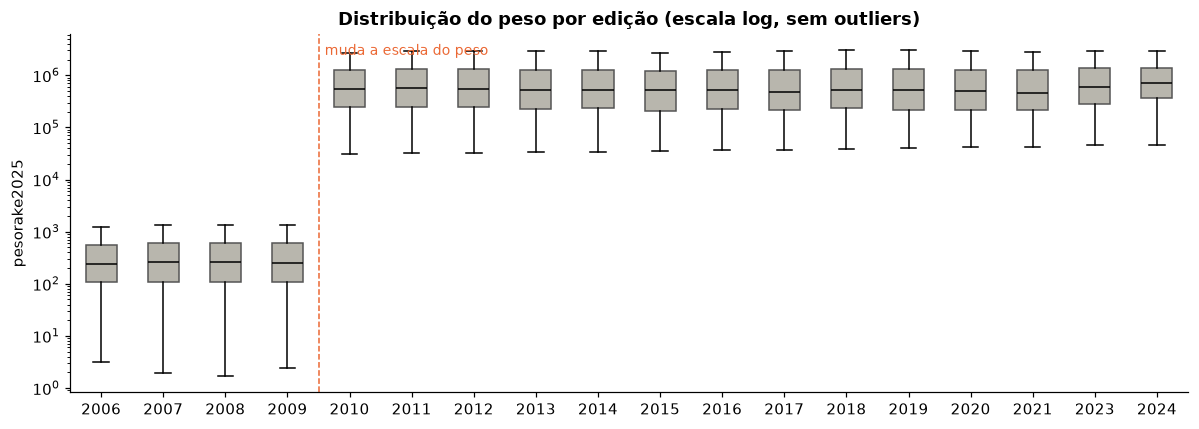

In [24]:
fig, ax = plt.subplots(figsize=(11, 4))
dados_box = [explo.loc[explo['ano'] == a, 'peso'] for a in ANOS]
ax.boxplot(dados_box, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=COR_OUTROS, edgecolor='#555'), medianprops=dict(color='black'))
ax.set_xticks(range(1, len(ANOS) + 1), [str(a) for a in ANOS])
ax.set_yscale('log')
ax.axvline(4.5, color=COR_REF, ls='--', lw=1)
ax.text(4.6, ax.get_ylim()[1] * 0.4, 'muda a escala do peso', color=COR_REF, fontsize=9)
ax.set_title('Distribuição do peso por edição (escala log, sem outliers)')
ax.set_ylabel('pesorake2025')
plt.tight_layout()
plt.show()

**Como ler o gráfico:** o eixo vertical está em escala log (cada marca é 10 vezes a anterior); a caixa contém os 50% centrais dos entrevistados, a linha preta é a mediana e os bigodes mostram o resto, sem os valores extremos.

**Leitura:**
1. **O salto entre 2009 e 2010 é mudança de escala, não de população.** Em 2006-2009 a mediana é de cerca de 250 e a soma, de cerca de 30 milhões, próxima da população adulta das capitais. De 2010 em diante a mediana é de cerca de 500 mil e a soma, de dezenas de bilhões, o que não pode ser população. As *Orientações* explicam que `pesorake2025`¹⁹ junta os pesos antigos (2006-2009) com os recalibrados pelo Censo 2022 (2010-2024), mas não explicam a escala. A coluna *soma / entrevistas* mostra que, de 2010 em diante, **a soma dos pesos acompanha o número de entrevistas** (peso médio estável, de 1,2 a 1,4 milhão), e não a população.
2. **Para a prevalência a escala não importa**, desde que cada ano seja calculado separadamente: prevalência = soma dos pesos de quem tem o evento ÷ soma de todos os pesos, e multiplicar todos os pesos de um ano por uma constante não muda a razão. **Importa** ao juntar anos numa mesma conta (seria preciso normalizar o peso de cada ano antes, decisões D3 e D4) e ao estimar totais de pessoas a partir de 2010 (sairiam em bilhões).
3. **A variação dentro do ano é proposital.** Em 2010 o maior peso é cerca de mil vezes o menor. Dois motivos: o Vigitel entrevista uma quantidade parecida de pessoas em cada capital, então um entrevistado de São Paulo representa muito mais gente que um de Palmas; e grupos que atendem menos o telefone recebem peso maior para compensar. O custo é a precisão, medida pelo *n* efetivo de Kish: com pesos desiguais, a amostra se comporta como se fosse menor. As margens de erro da seção 13 usam esse *n* menor.
4. **2023 e 2024 (correção da explicação dada na conversa de 16/10/2026).** Foi dito que os pesos subiram "porque a amostra encolheu". **Isso estava errado:** em 2020 e 2021 a amostra também caiu à metade e o peso médio não subiu; o que caiu foi a soma. Em 2023-2024 subiu só a **mediana** (532 mil em 2019; 602 mil em 2023; 698 mil em 2024), com a média estável: mudou o formato da distribuição. Hipótese a investigar, e não conclusão: mudança de composição da amostra com a entrada do celular. A tabela abaixo compara os pesos dos dois modos.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

In [25]:
explo[explo['ano'].isin([2023, 2024])].groupby(['ano', 'fone'])['peso'].describe()[['count', '25%', '50%', 'mean', '75%']].round(0)

count       25%        50%       mean        75%
ano  fone                                                       
2023 CELULAR  10832.0  242593.0   505840.0  1041171.0  1121752.0
     FIXO     10858.0  329739.0   733082.0  1616548.0  1646504.0
2024 CELULAR  24448.0  350220.0   647547.0  1153990.0  1232845.0
     FIXO      2600.0  950312.0  1937499.0  3344469.0  3716806.0

**Leitura:** os entrevistados por fixo recebem pesos bem maiores que os por celular (mediana de 733 mil contra 506 mil em 2023; 1,9 milhão contra 648 mil em 2024), porque o fixo alcança poucos jovens e o peso precisa compensar. A mistura dos dois modos explica parte da mudança de formato, mas não toda: em 2024 o próprio celular tem mediana acima da de 2019 (648 mil contra 532 mil). A hipótese da composição continua aberta; a tabela fica registrada como evidência para a decisão D2.

## 13. Prévia descritiva das perguntas (não é o teste das hipóteses)

As prevalências abaixo são **ponderadas** por `pesorake2025`¹⁹ e têm um intervalo de 95% **aproximado**, calculado com o *n* efetivo de Kish. O intervalo exato exige o desenho amostral completo, o que fica para a camada analítica. O objetivo aqui é só ver a forma dos dados antes de decidir o tratamento.

**O que é o IC 95%.** A pesquisa entrevista só uma parte dos jovens, então a prevalência calculada é uma estimativa. O intervalo de confiança de 95% é a faixa onde o valor verdadeiro provavelmente está; a **largura** é a distância entre as duas pontas. Quanto menos entrevistas, mais larga a faixa.

As linhas verticais marcam as rupturas registradas: a pergunta de doses atual a partir de 2010 (seção 11.3), a falta da edição de 2022 e a entrada do celular e do novo filtro em 2023-2024.

> ¹⁹ **pesorake2025**: variável derivada: peso amostral de pós-estratificação (rake) por sexo, faixa etária e escolaridade em cada capital. Recalibrado pelo Censo 2022 para 2010-2024; pesos antigos em 2006-2009. A escala muda em 2010, então só deve ser usado dentro de cada ano.

In [26]:
def marcar_rupturas(ax):
    ax.set_xticks(range(2006, 2025, 2))
    ax.set_xlim(2005.5, 2024.5)
    topo, base = ax.get_ylim()[1], ax.get_ylim()[0]
    ax.axvline(2009.5, color='#777', ls='--', lw=1)
    ax.text(2009.6, topo, ' pergunta\n "5 ou mais"', va='top', fontsize=8, color='#555')
    ax.axvspan(2021.5, 2022.5, color='#eeeeee', zorder=0)
    ax.axvline(2022.5, color='#777', ls=':', lw=1)
    ax.text(2022, topo, 'sem\n2022', ha='center', va='top', fontsize=8, color='#555')
    ax.text(2022.6, base, ' celular', va='bottom', fontsize=8, color='#555')


def linha(ax, r, cor, rotulo):
    ax.plot(r['ano'], r['prev'], marker='o', color=cor, label=rotulo, lw=2)
    ax.fill_between(r['ano'], r['ic95_inf'], r['ic95_sup'], color=cor, alpha=0.15, lw=0)

### 13.1 P1 e P3: jovens contra adultos de 35 a 44 anos

faixa,18 a 24,25 a 34,35 a 44,45 a 54,55 a 64,65 e mais
ano,,,,,,
2006,18.7,21.6,17.4,13.2,7.0,2.5
2007,22.7,21.7,16.7,14.4,9.4,2.7
2008,21.3,22.1,19.3,15.2,10.3,3.3
2009,23.4,23.9,20.0,16.8,10.4,4.1
2010,21.9,23.9,19.7,15.9,10.9,4.4
2011,20.1,21.2,18.4,14.7,10.7,4.4
2012,21.4,24.9,19.6,16.6,12.3,4.9
2013,19.0,22.4,17.6,15.0,10.6,4.0
2014,17.8,23.3,18.0,15.2,11.3,3.7


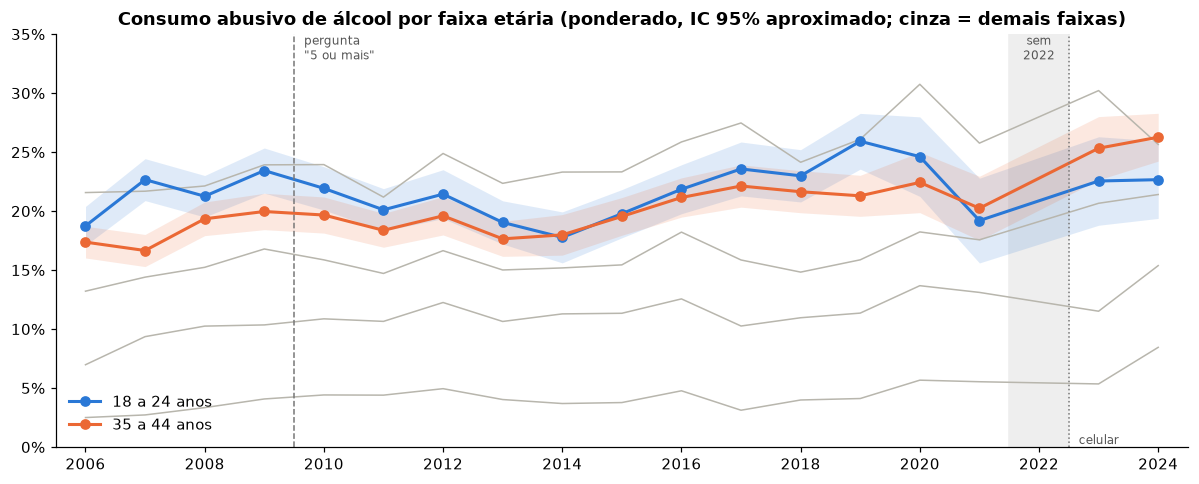

Variação 2010 -> 2024 (p.p.): {'18 a 24': 0.8, '35 a 44': 6.6}
Variação 2010 -> 2019 (p.p., só telefone fixo): {'18 a 24': 4.0, '35 a 44': 1.6}


In [27]:
por_faixa = prevalencia(explo, ['ano', 'fet'])
por_faixa['faixa'] = por_faixa['fet'].map(ROTULOS['fet'])
tabela_p1 = por_faixa.pivot(index='ano', columns='faixa', values='prev').round(1)
display(tabela_p1)

fig, ax = plt.subplots(figsize=(11, 4.5))
for f in ['2', '4', '5', '6']:
    r = por_faixa[por_faixa['fet'] == f]
    ax.plot(r['ano'], r['prev'], color=COR_OUTROS, lw=1)
linha(ax, por_faixa[por_faixa['fet'] == '1'], COR_JOVEM, '18 a 24 anos')
linha(ax, por_faixa[por_faixa['fet'] == '3'], COR_REF, '35 a 44 anos')
ax.set_ylim(0, 35)
marcar_rupturas(ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Consumo abusivo de álcool por faixa etária (ponderado, IC 95% aproximado; cinza = demais faixas)')
ax.legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.show()

v = tabela_p1.loc[[2010, 2019, 2024], ['18 a 24', '35 a 44']]
print('Variação 2010 -> 2024 (p.p.):', (v.loc[2024] - v.loc[2010]).round(1).to_dict())
print('Variação 2010 -> 2019 (p.p., só telefone fixo):', (v.loc[2019] - v.loc[2010]).round(1).to_dict())

**Leitura (prévia):** entre os jovens, a prevalência ponderada foi de 21,9% em 2010 e 22,7% em 2024 (+0,8 p.p.), **sem queda visível**; a faixa de 35 a 44 anos subiu 6,6 p.p. Como 2023-2024 trazem mudanças de método (seções 8 e 11.5), a comparação mais limpa é 2010 x 2019, toda por telefone fixo e com a mesma pergunta. Nela o quadro muda de lado: **os jovens sobem 4,0 p.p.** e a faixa de 35 a 44 anos, só 1,6 p.p. Ou seja, a alta das faixas mais velhas parece vir em boa parte de 2023-2024 (método), enquanto a dos jovens já existia antes. Em nenhuma das duas comparações a premissa do README (jovens bebendo menos) aparece.

### 13.2 P2: jovens por escolaridade

fesc,0 a 8 anos,9 a 11 anos,12 anos e mais
ano,,,
2006,22.5,17.4,18.7
2007,28.8,20.7,22.9
2008,22.8,19.5,24.0
2009,27.1,20.4,27.6
2010,22.5,18.5,27.7
2011,24.4,18.0,22.1
2012,25.3,17.8,26.3
2013,20.0,17.9,20.7
2014,21.1,15.9,20.0


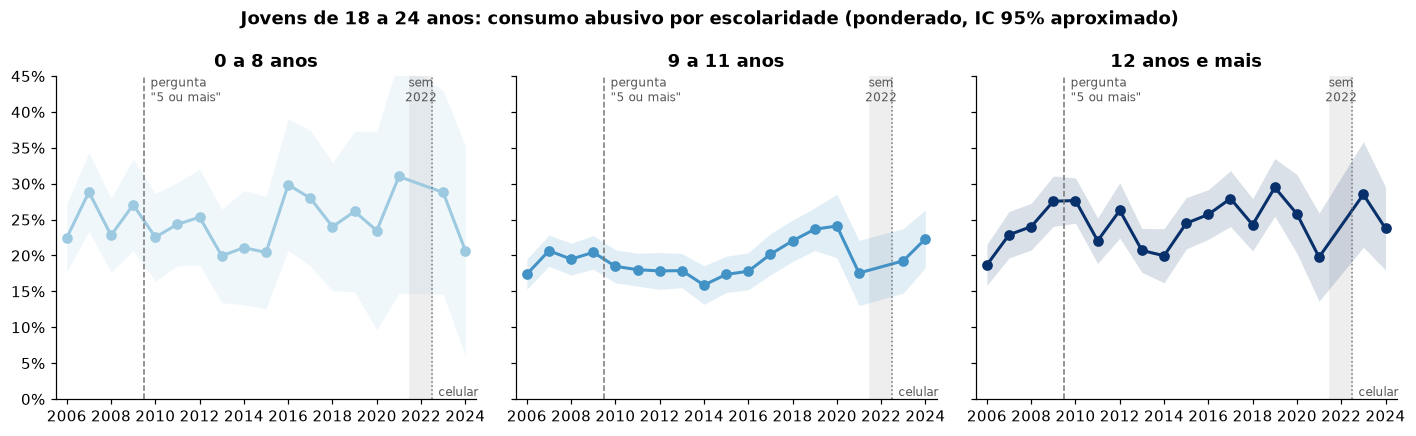

In [28]:
p2 = prevalencia(explo[jovem], ['ano', 'fesc'])
display(p2.pivot(index='ano', columns='fesc', values='prev')[list(CORES_ESC)].round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, faixa in zip(axes, CORES_ESC):
    linha(ax, p2[p2['fesc'] == faixa], CORES_ESC[faixa], faixa)
    ax.set_ylim(0, 45)
    marcar_rupturas(ax)
    ax.set_title(faixa)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
fig.suptitle('Jovens de 18 a 24 anos: consumo abusivo por escolaridade (ponderado, IC 95% aproximado)',
             fontweight='bold')
plt.tight_layout()
plt.show()

### 13.3 P4: jovens por sexo

sexo,feminino,masculino
ano,,
2006,9.8,27.7
2007,13.8,31.8
2008,14.4,27.8
2009,14.3,31.8
2010,14.8,28.9
2011,12.2,27.8
2012,13.6,29.1
2013,14.4,23.6
2014,12.0,23.5


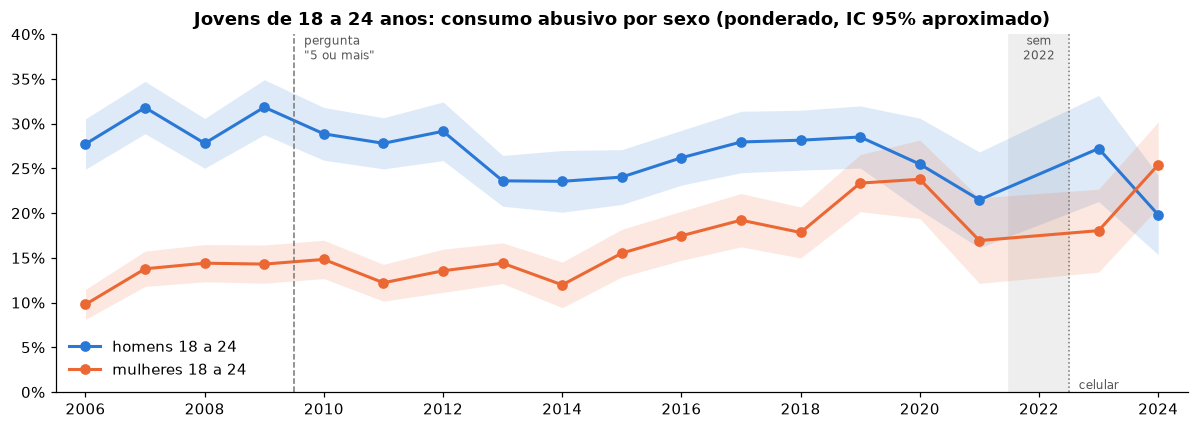

Sexo x faixa etária, 2010, 2019 e 2024 (prevalência ponderada, %)


ano                2010  2019  2024
sexo      faixa                    
feminino  18 a 24  14.8  23.4  25.4
          25 a 34  14.1  20.3  20.5
          35 a 44  10.9  14.6  20.5
masculino 18 a 24  28.9  28.5  19.8
          25 a 34  34.7  32.5  31.1
          35 a 44  30.5  29.3  32.7

In [29]:
p4 = prevalencia(explo[jovem], ['ano', 'sexo'])
display(p4.pivot(index='ano', columns='sexo', values='prev').round(1))

fig, ax = plt.subplots(figsize=(11, 4))
linha(ax, p4[p4['sexo'] == 'masculino'], COR_JOVEM, 'homens 18 a 24')
linha(ax, p4[p4['sexo'] == 'feminino'], COR_REF, 'mulheres 18 a 24')
ax.set_ylim(0, 40)
marcar_rupturas(ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title('Jovens de 18 a 24 anos: consumo abusivo por sexo (ponderado, IC 95% aproximado)')
ax.legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.show()

print('Sexo x faixa etária, 2010, 2019 e 2024 (prevalência ponderada, %)')
sxf = prevalencia(explo[explo['ano'].isin([2010, 2019, 2024]) & explo['fet'].isin(['1', '2', '3'])], ['sexo', 'fet', 'ano'])
sxf['faixa'] = sxf['fet'].map(ROTULOS['fet'])
display(sxf.pivot(index=['sexo', 'faixa'], columns='ano', values='prev').round(1))

**Leitura (prévia):** por escolaridade, as três faixas oscilam muito de um ano para outro (a faixa de 0 a 8 anos tem pouco mais de 100 jovens nas edições recentes), sem uma tendência comum clara. Por sexo aparece o movimento mais forte da prévia: entre as jovens a prevalência sobe de cerca de 15% (2010) para 25% (2024), e entre os jovens homens cai de cerca de 29% para 20%. A tabela por sexo e faixa etária ajuda a ler esses movimentos:
- **mulheres:** a alta das jovens já era visível em 2019 (só fixo), então resiste à troca de método; mas as mulheres de 25 a 44 anos subiram quase tanto, o que sugere uma mudança das mulheres em geral, e não da geração Z;
- **homens:** os jovens são o único grupo masculino que caiu, o que lembra um efeito de geração; mas a queda aparece só em 2024 (em 2019 o valor era igual ao de 2010), justamente o ano da amostra menor, do celular e do novo filtro.

### 13.4 P5: prevalência e precisão por capital

Cada capital aparece com a prevalência dos jovens (ponto) e o IC 95% (linha), em 2010 e em 2024, ordenada pela variação.

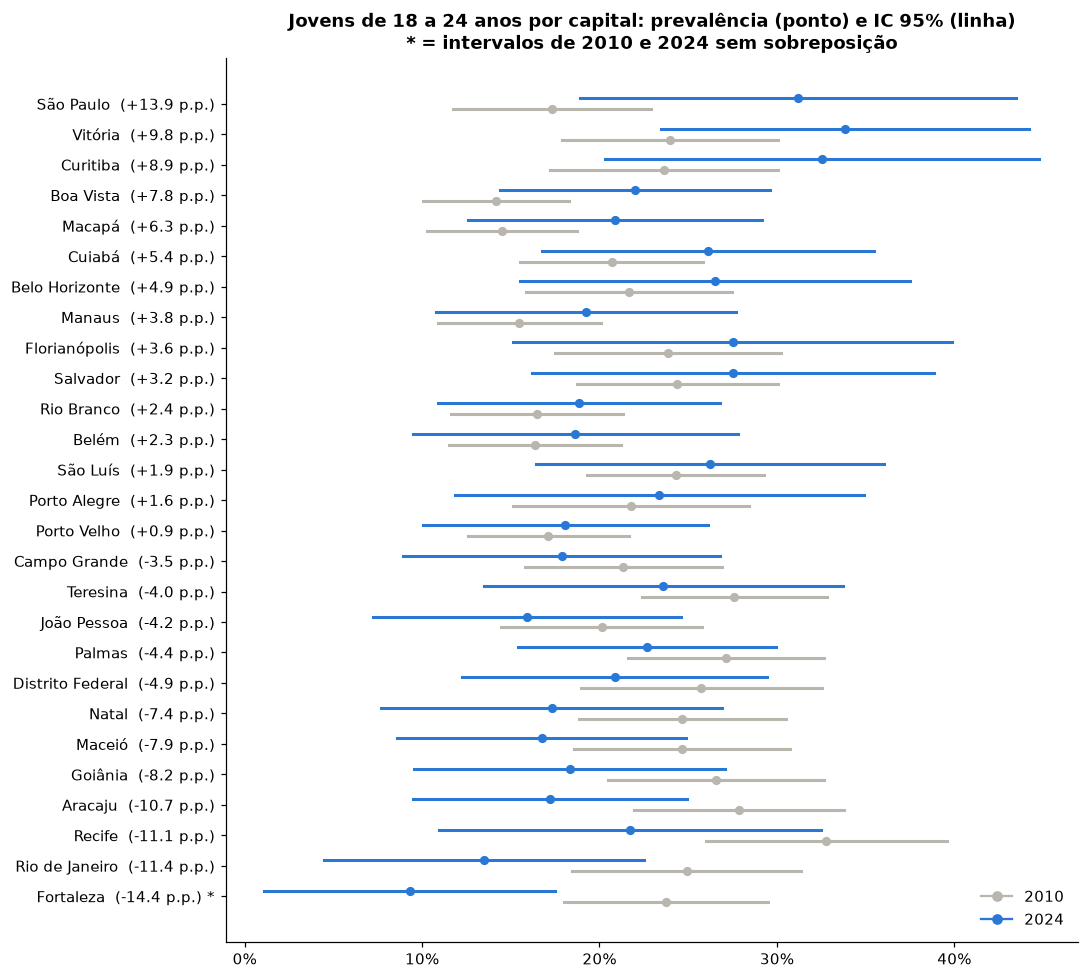

Capitais que subiram: 15 | caíram: 12 | sem sobreposição dos intervalos: ['Fortaleza']


,jovens (mediana),"largura do IC (mediana, p.p.)"
ano,,
2010,270.0,11.3
2024,84.0,18.0


In [30]:
p5 = prevalencia(explo[jovem & explo['ano'].isin([2010, 2024])], ['ano', 'cidade'])
p5['largura_ic'] = p5['ic95_sup'] - p5['ic95_inf']
largas = p5.pivot(index='cidade', columns='ano')
variacao = (largas['prev'][2024] - largas['prev'][2010]).sort_values()
sem_sobreposicao = ((largas['ic95_inf'][2024] > largas['ic95_sup'][2010]) |
                    (largas['ic95_sup'][2024] < largas['ic95_inf'][2010]))

fig, ax = plt.subplots(figsize=(10, 9))
for i, cidade in enumerate(variacao.index):
    for ano, cor, desloc in [(2010, COR_OUTROS, -0.18), (2024, COR_JOVEM, 0.18)]:
        r = p5[(p5['cidade'] == cidade) & (p5['ano'] == ano)].iloc[0]
        ax.plot([r['ic95_inf'], r['ic95_sup']], [i + desloc] * 2, color=cor, lw=2)
        ax.plot(r['prev'], i + desloc, 'o', color=cor, ms=5)
rotulos = [f'{c}  ({variacao[c]:+.1f} p.p.){" *" if sem_sobreposicao[c] else ""}' for c in variacao.index]
ax.set_yticks(range(len(variacao)), rotulos)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.plot([], [], 'o-', color=COR_OUTROS, label='2010')
ax.plot([], [], 'o-', color=COR_JOVEM, label='2024')
ax.legend(frameon=False, loc='lower right')
ax.set_title('Jovens de 18 a 24 anos por capital: prevalência (ponto) e IC 95% (linha)\n'
             '* = intervalos de 2010 e 2024 sem sobreposição')
plt.tight_layout()
plt.show()

print('Capitais que subiram:', (variacao > 0).sum(), '| caíram:', (variacao < 0).sum(),
      '| sem sobreposição dos intervalos:', list(sem_sobreposicao[sem_sobreposicao].index))
display(p5.groupby('ano')[['n', 'largura_ic']].median().round(1).rename(columns={'n': 'jovens (mediana)', 'largura_ic': 'largura do IC (mediana, p.p.)'}))

**Leitura:** 15 capitais subiram e 12 caíram, sem um movimento comum. As maiores altas (São Paulo, Vitória, Curitiba) e quedas (Fortaleza, Rio de Janeiro, Recife) têm intervalos largos: em 2024 a mediana é de cerca de 85 jovens por capital e a largura mediana do intervalo, de cerca de 18 p.p. (era cerca de 11 em 2010). Florianópolis, por exemplo, tem 53 jovens em 2024 e intervalo de 15% a 40%. Só em Fortaleza os intervalos de 2010 e 2024 não se sobrepõem. A sobreposição é um critério aproximado; o teste formal fica para a camada analítica. Para a P5, um ranking de capitais com 2024 isolado seria enganoso: será preciso juntar anos ou agrupar regiões (decisões D3 e D9).

## 14. Decisões de tratamento (tomadas pelo autor em 16/10/2026)

Cada problema da exploração foi apresentado ao autor com opções, prós e contras, uma decisão de cada vez. A tabela resume a decisão e o motivo; as alternativas descartadas e as evidências estão no *Relatório de Análise Exploratória de Dados v3*, seção 6, e em `DECISOES_TRATAMENTO.md`.

| # | Problema | Decisão | Motivo do autor |
|---|---|---|---|
| D1 | Não existe 2022 | Manter a lacuna à vista, sem criar valor | "Para não criar nenhum dado" |
| D2 | Método muda entre 2010 e 2024 | Comparar **gerações** aos 18-24 anos: millennials (1986-1992), zillennials (1993-1998), geração Z (1999-2006); README reformulado | Ver os recortes da geração Z e a transição zillennial, mantendo uma pergunta de negócio |
| D3 | Amostra pequena num ano isolado | Resolvida pela D2: cada geração junta as edições em que foi observada | Consequência da D2 |
| D4 | Pesos com escalas diferentes | Normalizar o peso de cada edição para somar 1 | Necessária para juntar edições |
| D5 | Pergunta de doses mudou em 2010 | Só edições de 2010 em diante; filtro pelo ano | "Para não ter que explicar mais uma mudança de pergunta" |
| D6 | `q35`³ muda e não existe em 2024 | Decompor: bebe ao menos 1x/mês (`q36`⁴) x abusivo entre quem bebe; `q35`³ só como conferência até 2023 | Ver o que a `q35`³ revela sem perder 2024 |
| D7 | Composição por escolaridade mudou | P2 dentro de cada faixa e, na P1, média padronizada ao lado da real | "Me parece mais completa" |
| D8 | `fesc`¹⁷ estimada pelo Ministério | Aceitar e refazer a P2 sem os casos estimados | Opção sugerida: mantém todos e prova com número |
| D9 | Poucos jovens por capital | Capitais em primeiro plano, com margem de erro; região como apoio | "A decisão deve ser valiosa a empresários de vários lugares do Brasil" |
| D10 | Sem identificador confiável | Chave = edição + linha do arquivo | Opção sugerida: única e rastreável |
| D11 | 2020-2021 na pandemia | Manter, com sensibilidade sem esses anos | Opção sugerida: a pandemia faz parte dessas gerações |
| D12 | Texto livre e `regiao` vazia em 2012 | Texto livre só na bronze; região derivada da capital | "Para remover risco de dado pessoal" |
| D13 | Filtro novo em 2024 | Manter 2024, com sensibilidade sem 2024 | "Fecha as duas mudanças de 2024 com um único teste" |

> ³ **q35**: pergunta, a todos: "O(a) Sr.(a) costuma consumir bebida alcoólica?". 2007-2019: 1 = sim, 2 = não. 2023: 1 = sim, 2 = não, 3 = nunca, 888 = não quis informar. 2006 e 2020-2021 têm outras codificações. Não existe em 2024: foi substituída por R501 e R502.

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

> ¹⁷ **fesc**: variável derivada: faixa de escolaridade a partir de q8_anos. 1 = 0 a 8 anos, 2 = 9 a 11, 3 = 12 e mais. Imputada pelo Ministério quando q8a = 777 ou 888, porque entra na calibração do peso.

## 15. Prévia com as decisões aplicadas (formulação por geração)

A célula abaixo monta uma **camada tratada local**, espelho da silver do pipeline (`scripts/vigitel_etl.py`, regras S1 a S11), só com o necessário para a prévia: edições de 2010 em diante (D5), geração pelo ano de nascimento (D2), peso normalizado por edição (D4), "bebe ao menos 1x por mês" pela `q36`⁴ (D6) e os marcadores das sensibilidades (D8, D11, D13). O código é repetido aqui para o notebook rodar sozinho no Colab; o pipeline usa o módulo.

> ⁴ **q36**: pergunta, só a quem bebe: "Com que frequência o(a) Sr.(a) costuma consumir alguma bebida alcoólica?". 1 = 1 a 2 dias por semana, 2 = 3 a 4, 3 = 5 a 6, 4 = todos os dias, 5 = menos de 1 dia por semana, 6 = menos de 1 dia por mês (pula as perguntas de doses). 2006 usa outra codificação.

In [31]:
GERACOES = {'millennials': (1986, 1992), 'zillennials': (1993, 1998), 'geracao_z': (1999, 2006)}
ORDEM_GER = list(GERACOES)

tratada = explo[explo['ano'] >= 2010].copy()                                   # D5
tratada['ano_nascimento'] = tratada['ano'] - tratada['idade']                   # D2
tratada['geracao'] = 'outra'
for g, (ini, fim) in GERACOES.items():
    tratada.loc[tratada['ano_nascimento'].between(ini, fim), 'geracao'] = g
tratada['peso_norm'] = tratada['peso'] / tratada.groupby('ano')['peso'].transform('sum')   # D4
tratada['bebe_mensal'] = q36_txt[tratada.index].isin(['1', '2', '3', '4', '5']).astype(int)  # D6
tratada['escolaridade_estimada'] = bruto.loc[tratada.index, 'q8a'].isin(['777', '888'])     # D8
tratada['modo'] = np.where(tratada['ano'] <= 2021, 'fixo', tratada['fone'].str.lower())

assert np.allclose(tratada.groupby('ano')['peso_norm'].sum(), 1)
assert (tratada.loc[tratada['bebe_mensal'] == 0, 'alcabu'] == 0).all()
jov = tratada[(tratada['fet'] == '1') & tratada['geracao'].isin(ORDEM_GER)]
print(f'Camada tratada local: {len(tratada):,} entrevistas de 2010 em diante; jovens das três gerações: {len(jov):,}')
pd.crosstab(jov['geracao'], jov['ano']).loc[ORDEM_GER]

Camada tratada local: 615,877 entrevistas de 2010 em diante; jovens das três gerações: 61,035


ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2023,2024
geracao,,,,,,,,,,,,,,
millennials,7364,5847,3756,3173,1748,1258,659,0,0,0,0,0,0,0
zillennials,0,1124,1597,2661,2568,3792,4504,3800,3202,2235,812,450,0,0
geracao_z,0,0,0,0,0,0,0,710,1331,1796,1263,1267,1824,2294


### 15.1 P1: consumo abusivo aos 18-24 anos, por geração (real e padronizado pela escolaridade, D7)

In [32]:
def prev_w(df, por, y='alcabu'):
    return prevalencia(df.assign(peso=df['peso_norm'], alcabu=df[y]), por)


t_p1 = prev_w(jov, ['geracao']).set_index('geracao').loc[ORDEM_GER]
comp = jov[jov['geracao'] == 'millennials'].groupby('fesc')['peso_norm'].sum()
comp = comp / comp.sum()
por_esc = prev_w(jov, ['geracao', 'fesc'])
por_esc['w'] = por_esc['fesc'].map(comp)
t_p1['prev_padronizada'] = (por_esc.assign(c=por_esc['prev'] * por_esc['w']).groupby('geracao')['c'].sum())
t_p1['ep'] = (t_p1['prev'] / 100 * (1 - t_p1['prev'] / 100) / t_p1['n_efetivo']) ** 0.5 * 100
for g in ['zillennials', 'geracao_z']:
    d = t_p1.loc[g, 'prev'] - t_p1.loc['millennials', 'prev']
    ep = np.hypot(t_p1.loc[g, 'ep'], t_p1.loc['millennials', 'ep'])
    print(f'{g} - millennials: {d:+.1f} p.p. (IC 95% {d - 1.96 * ep:+.1f} a {d + 1.96 * ep:+.1f})')
t_p1 = t_p1.reset_index()
t_p1[['geracao', 'n', 'prev', 'ic95_inf', 'ic95_sup', 'prev_padronizada']].round(1)

zillennials - millennials: -1.6 p.p. (IC 95% -3.0 a -0.2)
geracao_z - millennials: -2.1 p.p. (IC 95% -3.9 a -0.2)


,geracao,n,prev,ic95_inf,ic95_sup,prev_padronizada
0,millennials,23805,22.8,21.8,23.9,22.8
1,zillennials,26745,21.3,20.3,22.2,21.5
2,geracao_z,10485,20.8,19.2,22.3,21.3


**Leitura (prévia):** aos 18-24 anos, o consumo abusivo cai de 22,8% (millennials) para 21,3% (zillennials) e 20,8% (geração Z): cerca de −2 pontos, com intervalo que não inclui o zero. A média padronizada pela escolaridade dos millennials fica muito perto da real, então a diferença **não vem da mudança de escolaridade** (D7).

### 15.2 Decomposição por sexo (D6): bebem menos vezes ou exageram menos?

In [33]:
linhas = []
for (g, sx), d in jov.groupby(['geracao', 'sexo']):
    bebem = d[d['bebe_mensal'] == 1]
    w = lambda x, y: np.average(x[y], weights=x['peso_norm']) * 100
    linhas.append(dict(geracao=g, sexo=sx, n=len(d), abusivo=w(d, 'alcabu'), bebe_mensal=w(d, 'bebe_mensal'),
                       abusivo_entre_quem_bebe=w(bebem, 'alcabu')))
t_dec = pd.DataFrame(linhas)
t_dec['geracao'] = pd.Categorical(t_dec['geracao'], ORDEM_GER)
t_dec = t_dec.sort_values(['sexo', 'geracao'])
t_dec.round(1)

,geracao,sexo,n,abusivo,bebe_mensal,abusivo_entre_quem_bebe
2,millennials,feminino,12643,15.4,26.8,57.5
4,zillennials,feminino,13552,17.0,28.6,59.7
0,geracao_z,feminino,5321,19.3,33.0,58.6
3,millennials,masculino,11162,30.3,46.1,65.7
5,zillennials,masculino,13193,25.5,40.0,63.7
1,geracao_z,masculino,5164,22.2,38.6,57.4


**Leitura (prévia):** nos homens, o consumo abusivo cai de 30,3% para 22,2%, e as duas partes caem: menos homens jovens bebem pelo menos uma vez por mês (46% → 39%) e, entre os que bebem, menos exageram (66% → 57%). Nas mulheres, o consumo abusivo sobe de 15,4% para 19,3%, porque **mais mulheres jovens bebem** (27% → 33%), enquanto o exagero entre as que bebem fica estável (cerca de 58%). A distância entre os sexos cai de 15 para 3 pontos.

### 15.3 Sensibilidades: geração Z − millennials, em pontos percentuais

In [34]:
cenarios = {
    'base': jov,
    'só 18 a 21 anos': jov[jov['idade'] <= 21],
    'sem 2024 (filtro novo e celular)': jov[jov['ano'] != 2024],
    'geração Z só por telefone fixo': jov[(jov['geracao'] != 'geracao_z') | (jov['modo'] == 'fixo')],
    'sem 2020 e 2021 (pandemia)': jov[~jov['ano'].isin([2020, 2021])],
    'sem escolaridade estimada': jov[~jov['escolaridade_estimada']],
}
linhas = []
for nome, d in cenarios.items():
    linha = {'cenário': nome}
    for rot, sub in [('total', d), ('homens', d[d['sexo'] == 'masculino']), ('mulheres', d[d['sexo'] == 'feminino'])]:
        t = prev_w(sub, ['geracao']).set_index('geracao')
        linha[rot] = t.loc['geracao_z', 'prev'] - t.loc['millennials', 'prev']
    linhas.append(linha)
t_sens = pd.DataFrame(linhas)
t_sens.round(1)

,cenário,total,homens,mulheres
0,base,-2.1,-8.1,3.9
1,só 18 a 21 anos,-0.3,-6.6,6.6
2,sem 2024 (filtro novo e celular),-2.6,-7.5,2.2
3,geração Z só por telefone fixo,-3.8,-8.8,0.9
4,sem 2020 e 2021 (pandemia),-1.7,-8.2,4.8
5,sem escolaridade estimada,-2.1,-8.2,3.9


**Leitura (prévia):** a direção se mantém em todos os cenários: os homens da geração Z bebem em excesso de 6,6 a 8,8 pontos a menos que os millennials na mesma idade, e as mulheres, de 0,9 a 6,6 pontos a mais. Restringindo à geração Z entrevistada só por telefone fixo, a queda masculina fica até maior, o que confirma que ela não é efeito do celular. Comparando só aos 18-21 anos, o total fica perto de zero, porque a queda dos homens e a alta das mulheres se compensam. O teste formal, com os critérios do README e as perguntas P2 a P5, fica no notebook `05_analise_hipoteses` do pipeline.

## 16. Integridade e saídas

In [35]:
assert pd.util.hash_pandas_object(bruto, index=True).sum() == DIGITAL_BRUTO, 'O bruto foi alterado!'
print('Bruto intacto: a impressão digital é a mesma da leitura.')

os.makedirs(PASTA_SAIDAS, exist_ok=True)
saidas = {
    'amostra_por_ano.csv': amostra,
    'vazios_classificados_por_coluna.csv': classificacao,
    'vazios_pulo_por_ano.csv': mapas['pulo legítimo'].round(2),
    'vazios_inexistente_por_ano.csv': mapas['inexistente no ano'].round(2),
    'vazios_faltante_por_ano.csv': mapas['faltante de verdade'].round(2),
    'conferencia_pulo_doses.csv': conferencia,
    'pesos_por_ano.csv': pesos,
    'prevalencia_por_modo_2023_2024.csv': prev_modo,
    'previa_prevalencia_faixa_etaria.csv': por_faixa,
    'previa_prevalencia_jovens_escolaridade.csv': p2,
    'previa_prevalencia_jovens_sexo.csv': p4,
    'previa_prevalencia_sexo_faixa.csv': sxf,
    'previa_prevalencia_jovens_capital.csv': p5,
    'tratada_p1_geracao.csv': t_p1,
    'tratada_decomposicao_sexo.csv': t_dec,
    'tratada_sensibilidades.csv': t_sens,
}
for nome, tabela in saidas.items():
    tabela.to_csv(os.path.join(PASTA_SAIDAS, nome), encoding='utf-8-sig')
print(f'{len(saidas)} tabelas salvas em {PASTA_SAIDAS}')

Bruto intacto: a impressão digital é a mesma da leitura.
16 tabelas salvas em saidas_aed_v3


## 17. Síntese e próximos passos

1. **A exploração (seções 1 a 13)** mostrou que os vazios não são o problema e que o método da pesquisa muda justamente nas pontas da comparação original (pergunta de doses nova em 2010; celular e filtro novo em 2023-2024).
2. **O autor tomou as 13 decisões** (seção 14). A principal foi trocar a comparação entre anos pela comparação entre gerações na mesma idade, o que dá precisão e deixa a comparação millennials x zillennials livre de mudança de método.
3. **A prévia com as decisões aplicadas (seção 15)** indica queda do consumo abusivo aos 18-24 anos da geração Z em relação aos millennials, puxada pelos homens, enquanto as mulheres sobem. Mais mulheres jovens bebem; menos homens jovens bebem, e os que bebem exageram menos. As sensibilidades não mudam a direção.
4. **Próximo passo:** executar o pipeline (`notebooks/01` a `05`) no Databricks, que aplica as mesmas regras na camada silver, carrega o modelo estrela e faz o teste formal da hipótese com os critérios do README.